<p class="lead">Este notebook amplía la octava unidad del curso, en la que el perceptrón multicapa de la Unidad 6 se encuentra con los datos que hicieron famosas a las redes neuronales en medicina: las imágenes. Las diapositivas de clase son un mapa; este texto es el territorio. Cada figura y cada número que aparecen a continuación los produce código que puedes ejecutar y modificar. Las secciones 4 y 5 entrenan perceptrones con imágenes, los evalúan con la metodología del Suplemento S1 y varían su topología —profundidad, ancho, activación, regularización, optimizador— en un diseño controlado que muestra qué mejora la clasificación y qué solo aparenta mejorarla. Las secciones 6 y 7 se preguntan <em>por qué</em> un perceptrón es un clasificador de imágenes poco adecuado, construyen a mano la operación de convolución y reproducen, en radiografías simuladas, la falla más documentada de la IA en imágenes médicas: una red que aprende el hospital en lugar de la enfermedad.</p>

<div class="box key"><h4>Objetivos de aprendizaje</h4>
<ul class="objectives">
<li>Explicar qué significa el valor de un píxel en cada una de las principales modalidades de imagen, representar una imagen como matriz y como vector de características, y describir el pipeline de reconocimiento de patrones de la Unidad 1 tal como se aplica a las imágenes.</li>
<li>Aplicar y justificar los pasos estándar de preprocesamiento —normalización de intensidades, ecualización del histograma, redimensionamiento, eliminación de ruido gaussiana y aumento de datos (data augmentation)— e indicar cuáles preservan la etiqueta de clase y cuáles no.</li>
<li>Calcular características de primer orden, de textura (co-ocurrencia de niveles de gris) y de forma a partir de una imagen, construir a mano la matriz de co-ocurrencia y entrenar con ellas los clasificadores de las Unidades 3–4 como línea base clásica.</li>
<li>Entrenar un perceptrón multicapa con imágenes aplanadas, evaluarlo con validación cruzada estratificada repetida, leer su matriz de confusión, visualizar los pesos de su primera capa y elegir un umbral de decisión para un contexto de tamizaje.</li>
<li>Diseñar y reportar un experimento honesto sobre la topología de la red: una grilla factorial evaluada con validación cruzada repetida, la varianza entre pliegues, curvas de aprendizaje y validación cruzada anidada para la estimación final.</li>
<li>Explicar la invariancia a la traslación, desarrollar a mano una convolución bidimensional y un paso de max-pooling, implementar ambos en numpy y mostrar por qué una etapa convolucional inicial es el puente entre el perceptrón y el aprendizaje profundo.</li>
<li>Reproducir el aprendizaje por atajos (shortcut learning) en datos de imagen, construir un mapa de sensibilidad a la oclusión que lo revele, y describir el desbalance de clases, el ruido en las etiquetas, la validación externa, los estudios con lectores y la situación regulatoria de la IA en imágenes.</li>
<li>Leer críticamente los artículos fundamentales de la IA en imágenes médicas: identificar la muestra, el estándar de referencia, la métrica, el comparador y lo que falta.</li>
</ul></div>

<div class="box bridge"><h4>Cómo leer este notebook</h4>
<p>Léelo una vez de principio a fin, ejecutando cada celda a medida que llegas a ella; luego vuelve a los experimentos de las secciones 5–7 y cambia un factor a la vez. Los ejercicios (cajas verdes) te piden modificar la celda que está sobre ellos. Las cajas azules contienen ideas clave, las naranjas errores frecuentes y las moradas conectan esta unidad con otras unidades o con el curso de bioinformática (BGM324). El notebook usa solo <code>numpy</code>, <code>scipy</code>, <code>pandas</code>, <code>matplotlib</code> y <code>scikit-learn</code>; no se usa ningún framework de aprendizaje profundo, porque el objetivo es entender las operaciones, no ejecutar una biblioteca. A lo largo del notebook se usan dos fuentes de imágenes: los 1,797 dígitos manuscritos incluidos en scikit-learn (8 × 8 píxeles), que sirven como un benchmark de imágenes real y pequeño, y un <strong>generador sintético de parches similares a radiografías</strong> escrito en la Sección 1.3. Las imágenes sintéticas son simulaciones construidas para controlar el experimento —la posición, el tamaño y el contraste de la lesión se conocen porque los elegimos nosotros— y no son radiografías; la Sección 1.3 enumera los conjuntos de datos reales que debes conocer.</p></div>

In [1]:
# Configuración: bibliotecas usadas en todo el notebook. Las semillas se fijan para que cada número
# citado en el texto sea reproducible. Las advertencias de convergencia del perceptrón se silencian a propósito:
# varios experimentos detienen el entrenamiento antes de tiempo deliberadamente, y la advertencia inundaría la salida.
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy, sklearn
from scipy import ndimage, signal, stats
from sklearn import datasets
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

np.random.seed(0)
pd.set_option("display.width", 130); pd.set_option("display.max_columns", 14)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "image.cmap": "gray"})
print("numpy", np.__version__, "| scipy", scipy.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.4.6 | scipy 1.17.1 | pandas 3.0.3 | scikit-learn 1.9.0


## 1. Las imágenes médicas como patrones

### 1.1 Qué significa un píxel

Una imagen médica es una medición, y un clasificador que la lee hereda la física de esa medición. La revisión de Litjens y colaboradores, que catalogó más de 300 artículos de aprendizaje profundo sobre imágenes médicas hasta 2017, organiza el campo por modalidad precisamente por esta razón: lo que una red puede aprender depende de lo que codifican los números de la imagen.<sup class="c"><a href="#r1">[1]</a></sup> La tabla siguiente resume las modalidades que encontrarás en la literatura de esta unidad.

| Modalidad | Qué codifica el valor de un píxel (o vóxel) | Tamaño y profundidad de bits típicos | Tareas de clasificación en la literatura |
|---|---|---|---|
| **Radiografía de proyección** (rayos X) | Atenuación integrada de los rayos X a lo largo de la trayectoria del haz; el tejido denso (hueso, metal) atenúa más y por convención aparece brillante | 2,000–3,000 px por lado; 12–16 bits | neumonía, nódulos, fracturas, las 14 etiquetas torácicas de ChestX-ray14 |
| **Tomografía computarizada** (CT) | Coeficiente de atenuación lineal $\mu$ de un pequeño volumen, expresado en **unidades Hounsfield** $\mathrm{HU} = 1000 \,(\mu - \mu_{\text{water}})/(\mu_{\text{water}} - \mu_{\text{air}})$, de modo que el agua vale 0, el aire alrededor de −1000 y el hueso cortical alrededor de +1000<sup class="c"><a href="#r2">[2]</a></sup> | 512 × 512 por corte, cientos de cortes; 12 bits | nódulos pulmonares, hemorragia, neumonía por COVID-19, segmentación de órganos |
| **Resonancia magnética** (MRI) | Señal de los núcleos de hidrógeno tras la excitación por radiofrecuencia; depende de la densidad de protones, de los tiempos de relajación (T1, T2) y de la secuencia de pulsos — **unidades arbitrarias**, no comparables entre equipos sin normalización | 256 × 256 por corte; 12–16 bits | gradación de tumores cerebrales, lesiones de esclerosis múltiple, cáncer de próstata |
| **Ultrasonido** | Amplitud del eco devuelto por las interfaces de impedancia acústica, con ruido speckle intrínseco al método | 500–1,000 px por lado; 8 bits | lesiones mamarias, nódulos tiroideos, mediciones fetales |
| **Histopatología** (imágenes de lámina completa) | Color del tejido teñido bajo luz transmitida; tres canales (RGB); la tinción (H&E) es un contraste químico, no físico | 100,000 px por lado, procesadas en teselas; 8 bits por canal | detección de tumores, gradación, conteo de mitosis |
| **Dermatoscopía** | Luz reflejada por la superficie de la piel bajo aumento y polarización; RGB | 1,000–6,000 px por lado; 8 bits por canal | melanoma frente a nevo benigno (ISIC) |
| **Fotografía de retina** (fondo de ojo) | Luz reflejada por la retina a través de la pupila; RGB | 2,000–4,000 px por lado; 8 bits por canal | gradación de la retinopatía diabética, glaucoma |

De esto se siguen tres consecuencias. Los valores de CT son magnitudes físicas en una escala común, de modo que un umbral de −500 HU significa lo mismo en todos los equipos; los valores de MRI y de ultrasonido no lo son, por lo que la **normalización de intensidades** (Sección 2.1) es obligatoria antes de entrenar con imágenes de más de una máquina. Las imágenes clínicas tienen 12–16 bits de profundidad, pero se visualizan a través de una **ventana** (un rango de valores que se mapea a la escala de grises visible), de modo que un modelo entrenado con imágenes de 8 bits ventaneadas ve menos de lo que almacena la estación de trabajo. Y las imágenes se almacenan junto con sus parámetros de adquisición en el estándar **DICOM** (Digital Imaging and Communications in Medicine), cuyo encabezado registra el equipo, el protocolo, el espaciado de píxeles y, a menos que se elimine, la identidad del paciente: la desidentificación (Unidad 1) es una condición previa de todo conjunto de datos de imágenes, y los campos que sobreviven a ella —fabricante, institución— son precisamente los factores de confusión que, como muestra la Sección 7, una red puede explotar.

### 1.2 Imagen = matriz = vector

Una imagen con $H$ filas y $W$ columnas es una matriz $\mathbf{I} \in \mathbb{R}^{H \times W}$ cuyo elemento $I_{rc}$ es la intensidad del píxel en la fila $r$ y la columna $c$; una imagen en color agrega un tercer índice para el canal. Todos los clasificadores de las Unidades 2–6 esperan un *vector*, de modo que la matriz se aplana fila por fila en $\mathbf{x} = (I_{11}, I_{12}, \dots, I_{1W}, I_{21}, \dots, I_{HW})$ de longitud $p = H \cdot W$. El aplanamiento es reversible y no pierde nada —pero descarta la *adyacencia* de los píxeles: al clasificador no se le dice que $x_1$ y $x_2$ son vecinos, ni que $x_1$ y $x_{W+1}$ también lo son. La Sección 6 muestra que esta es la debilidad central del perceptrón como clasificador de imágenes. El primer conjunto de datos de la unidad es el que se presentó en la Unidad 1: 1,797 dígitos manuscritos, cada uno una imagen de 8 × 8 con 17 niveles de gris, recolectados de 43 personas por el repositorio UCI.<sup class="c"><a href="#r10">[10]</a></sup> La celda imprime uno de ellos como la matriz que es.

Image matrix (8 x 8 integers, 0 = white paper, 16 = darkest ink) of a 7 :
[[ 0  0  7  8 13 16 15  1]
 [ 0  0  7  7  4 11 12  0]
 [ 0  0  0  0  8 13  1  0]
 [ 0  4  8  8 15 15  6  0]
 [ 0  2 11 15 15  4  0  0]
 [ 0  0  0 16  5  0  0  0]
 [ 0  0  9 15  1  0  0  0]
 [ 0  0 13  5  0  0  0  0]]
Flattened: [ 0  0  7  8 13 16 15  1  0  0  7  7] ...  length 64


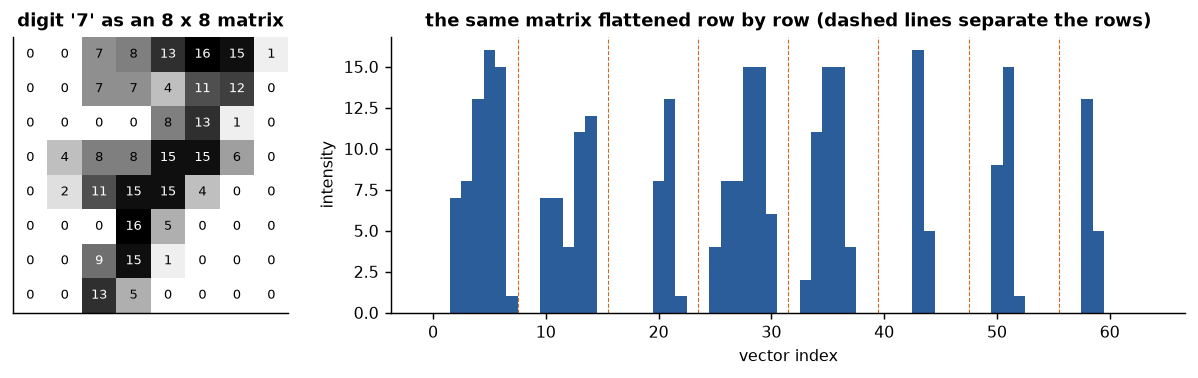

In [2]:
# Un dígito como matriz de enteros, y el mismo dígito como vector de 64 elementos.
digits = datasets.load_digits()
X_dig, y_dig, I_dig = digits.data, digits.target, digits.images          # (1797, 64), (1797,), (1797, 8, 8)
img = I_dig[7]
print("Image matrix (8 x 8 integers, 0 = white paper, 16 = darkest ink) of a", y_dig[7], ":")
print(img.astype(int))
print("Flattened:", X_dig[7][:12].astype(int), "...  length", X_dig[7].size)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3), gridspec_kw={"width_ratios": [1, 2.4]})
axes[0].imshow(img, cmap="gray_r")
for (r, c), v in np.ndenumerate(img):                                   # anota cada píxel con su valor
    axes[0].text(c, r, int(v), ha="center", va="center", fontsize=7, color="white" if v > 8 else "black")
axes[0].set_title(f"digit '{y_dig[7]}' as an 8 x 8 matrix"); axes[0].set_xticks([]); axes[0].set_yticks([])
axes[1].bar(range(64), X_dig[7], color="#2b5d9b", width=1.0)
for k in range(1, 8): axes[1].axvline(8 * k - 0.5, color="#d2691e", lw=0.6, ls="--")
axes[1].set_title("the same matrix flattened row by row (dashed lines separate the rows)")
axes[1].set_xlabel("vector index"); axes[1].set_ylabel("intensity")
fig.tight_layout()

<p class="caption"><b>Figura 1.</b> Izquierda: un dígito manuscrito como la matriz de 8 × 8 enteros que realmente contiene el archivo; la imagen es solo una representación visual de estos números. Derecha: el vector de 64 elementos que se obtiene al leer la matriz fila por fila; las líneas discontinuas marcan dónde termina una fila y comienza la siguiente. Para el perceptrón, el índice 7 (final de la primera fila) y el índice 8 (inicio de la segunda) son tan independientes entre sí como cualquier otro par, aunque en la imagen están alejados, y los índices 0 y 8 son vecinos verticales.</p>

### 1.3 Parches de radiografía simulados, y los conjuntos de datos reales a los que reemplazan

Los dígitos son imágenes reales, pero no son médicas, y un notebook público de un curso no puede incluir radiografías. Por eso, el segundo conjunto de datos de la unidad lo genera una función escrita más abajo. Cada imagen es un **parche** de 32 × 32 en niveles de gris que imita una pequeña región de una radiografía: una textura de fondo suave, como de nubes (una suma de campos aleatorios a tres escalas espaciales, al estilo del *ruido de Perlin* usado en computación gráfica), una exposición global aleatoria y ruido aditivo en los píxeles. Un parche positivo contiene además un **nódulo** —una mancha más brillante, aproximadamente redonda, de posición, radio y contraste aleatorios— o un grupo de **microcalcificaciones**, un puñado de puntos brillantes muy pequeños. La posición de la lesión se sortea alrededor del centro del parche con un **desplazamiento aleatorio** (jitter) controlable, porque así es como llegan los parches a un clasificador en un sistema de detección asistida por computador: un detector de candidatos propone una ubicación y un clasificador de segunda etapa decide si el candidato es una lesión o un falso positivo, el diseño del desafío de nódulos pulmonares LUNA16.<sup class="c"><a href="#r11">[11]</a></sup> Por último, el generador puede estampar un pequeño rectángulo brillante en una esquina de los parches positivos de un "hospital A" ficticio —el tipo de marcador de lateralidad, regla o anotación que llevan las radiografías reales y que, como muestra la Sección 7, una red aprenderá en lugar de la lesión.

<div class="box warn"><h4>Estas son simulaciones, no radiografías</h4><p>Los parches siguientes se generan con una docena de líneas de código para que el experimento pueda ser <em>controlado</em>: conocemos la posición, el tamaño y el contraste de cada lesión, podemos producir tantas imágenes como necesitemos, y podemos introducir un factor de confusión y eliminarlo. Nada de eso es posible con datos reales, y nada de lo que se aprenda sobre <em>qué tan bien</em> un modelo clasifica estos parches se transfiere a las radiografías. Lo que sí se transfiere es el comportamiento de los métodos: qué hace el preprocesamiento, por qué el perceptrón es sensible a la posición, cómo se aprende un atajo y cómo se revela. Los conjuntos de datos reales que debes conocer, todos públicos y todos construidos con el esfuerzo de etiquetado y desidentificación descrito en sus artículos, son: <strong>ChestX-ray14</strong>, 112,120 radiografías frontales de tórax de 30,805 pacientes con 14 etiquetas extraídas de los informes mediante minería de texto;<sup class="c"><a href="#r3">[3]</a></sup> <strong>CheXpert</strong>, 224,316 radiografías de 65,240 pacientes con etiquetas que registran la incertidumbre;<sup class="c"><a href="#r4">[4]</a></sup> <strong>MIMIC-CXR</strong>, 377,110 imágenes de 227,835 estudios con sus informes en texto libre;<sup class="c"><a href="#r5">[5]</a></sup> <strong>CBIS-DDSM</strong>, un subconjunto curado y re-segmentado de la Digital Database for Screening Mammography con patología verificada;<sup class="c"><a href="#r6">[6]</a></sup> <strong>HAM10000</strong>, 10,015 imágenes dermatoscópicas de lesiones pigmentadas, el conjunto de entrenamiento de los desafíos de melanoma ISIC;<sup class="c"><a href="#r7">[7]</a></sup> y <strong>MedMNIST v2</strong>, una colección de 18 conjuntos de datos pequeños y estandarizados (imágenes de 28 × 28) que es el paso natural después de este notebook.<sup class="c"><a href="#r8">[8]</a></sup> Recuerda también que los datos de cáncer de mama de Wisconsin usados a lo largo del curso son ellos mismos <em>derivados de imágenes</em>: las 30 características se calcularon a partir de micrografías digitalizadas de núcleos celulares mediante un programa de segmentación semiautomática,<sup class="c"><a href="#r9">[9]</a></sup> lo que constituye el pipeline de características diseñadas a mano de la Sección 3 aplicado en 1993.</p></div>

In [3]:
# Un generador reutilizable de parches simulados similares a radiografías (NO son imágenes reales; ver la caja anterior).
def perlin_background(size, rng, scales=(4, 8, 16), amplitudes=(1.0, 0.5, 0.25)):
    '''Smooth cloud-like texture: random grids at three spatial scales, interpolated and summed.'''
    img = np.zeros((size, size))
    for s, a in zip(scales, amplitudes):
        img += a * ndimage.zoom(rng.normal(size=(s + 1, s + 1)), size / (s + 1), order=3)[:size, :size]
    return img

def make_patches(n, lesion="nodule", jitter=3, hospital="B", marker_rate=0.0, size=32, positive=None,
                 contrast=(0.3, 0.6), rng=None):
    '''n patches (size x size, intensities in [0, 1]) and labels (1 = lesion present).
    lesion: "nodule" (round blob) or "microcalc" (cluster of bright points); jitter: max displacement
    of the lesion centre from the patch centre; hospital "A" stamps a corner marker on a fraction
    marker_rate of the POSITIVE patches (the confound of Section 7); positive=None draws labels at random.'''
    rng = np.random.default_rng(0) if rng is None else rng
    X, y = np.zeros((n, size, size)), np.zeros(n, int)
    yy, xx = np.mgrid[:size, :size]
    for i in range(n):
        img = perlin_background(size, rng)
        img = (img - img.mean()) / (img.std() + 1e-9) * 0.10 + 0.45 + rng.uniform(-0.08, 0.08)   # textura + exposición
        pos = (rng.random() < 0.5) if positive is None else bool(positive)
        cx, cy = size / 2 - 0.5 + rng.uniform(-jitter, jitter, 2)                                 # centro de la lesión
        if pos and lesion == "nodule":
            r, c = rng.uniform(3, 6), rng.uniform(*contrast)
            img += c * np.exp(-((xx - cx) ** 2 + (yy - cy) ** 2) / (2 * (r / 2) ** 2))
        elif pos and lesion == "microcalc":
            for _ in range(rng.integers(5, 10)):
                px, py = np.clip(np.round([cx, cy] + rng.normal(0, 2.5, 2)), 0, size - 1).astype(int)
                img[py, px] += rng.uniform(0.35, 0.6)
        if hospital == "A" and pos and rng.random() < marker_rate:
            img[1:4, size - 6:size - 1] = 1.0                                                     # marcador en la esquina
        img += rng.normal(0, 0.03, (size, size))                                                  # ruido del detector
        X[i], y[i] = np.clip(img, 0, 1), int(pos)
    return X, y

nod_X, nod_y = make_patches(1000, "nodule", rng=np.random.default_rng(0))
mc_X, mc_y = make_patches(1000, "microcalc", rng=np.random.default_rng(1))
print("nodule set:", nod_X.shape, "| positives:", nod_y.sum(), "| mean intensity: negatives %.3f, positives %.3f" %
       (nod_X[nod_y == 0].mean(), nod_X[nod_y == 1].mean()))
print("microcalcification set:", mc_X.shape, "| positives:", mc_y.sum())

nodule set: (1000, 32, 32) | positives: 502 | mean intensity: negatives 0.450, positives 0.464
microcalcification set: (1000, 32, 32) | positives: 498


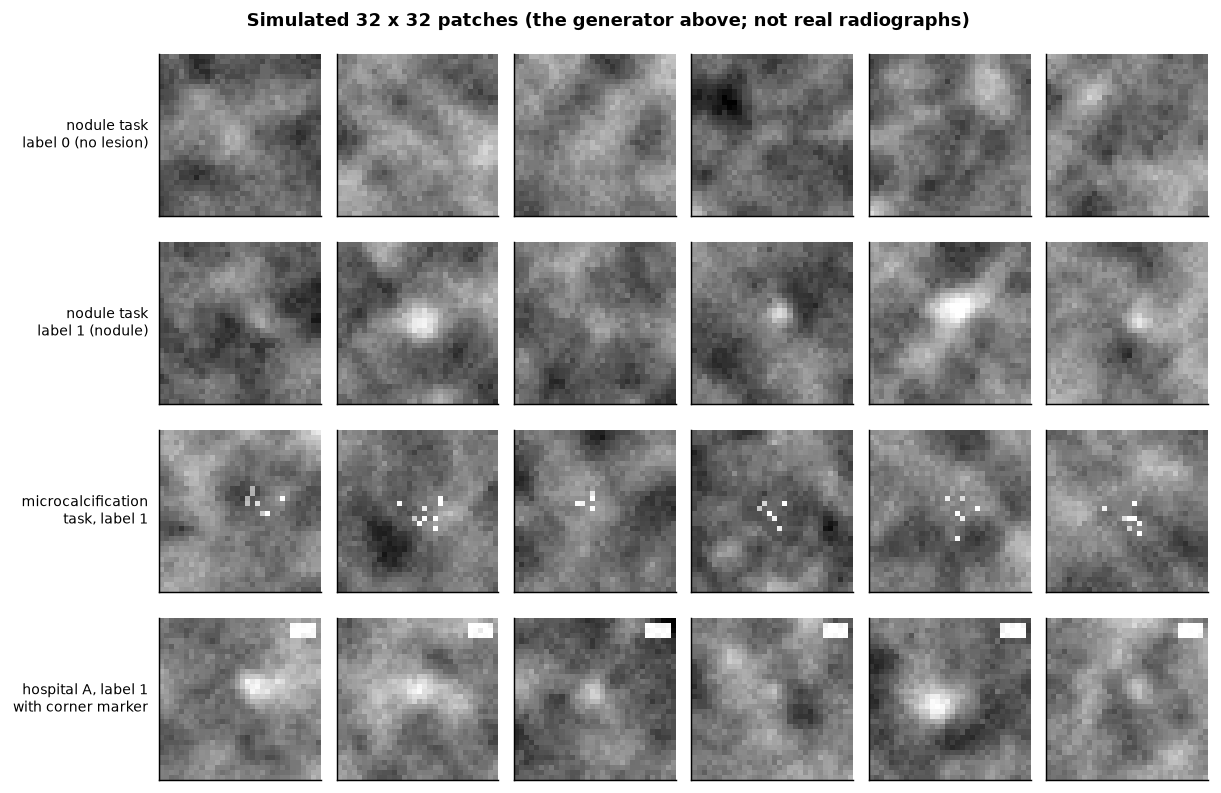

In [4]:
# Ejemplos de cada clase de cada tarea, y de los parches del 'hospital A' que llevan un marcador en la esquina.
hA_X, hA_y = make_patches(16, "nodule", hospital="A", marker_rate=1.0, rng=np.random.default_rng(5))
rows = [("nodule task\nlabel 0 (no lesion)", nod_X[nod_y == 0][:6]), ("nodule task\nlabel 1 (nodule)", nod_X[nod_y == 1][:6]),
        ("microcalcification\ntask, label 1", mc_X[mc_y == 1][:6]), ("hospital A, label 1\nwith corner marker", hA_X[hA_y == 1][:6])]
fig, axes = plt.subplots(4, 6, figsize=(9.5, 6.2))
for r, (title, imgs) in enumerate(rows):
    for c in range(6):
        axes[r, c].imshow(imgs[c], vmin=0, vmax=1); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(title, fontsize=8, rotation=0, ha="right", va="center", labelpad=6)
fig.suptitle("Simulated 32 x 32 patches (the generator above; not real radiographs)", fontsize=10, fontweight="bold")
fig.tight_layout()

<p class="caption"><b>Figura 2.</b> Seis ejemplos de cada tipo de parche simulado. Los nódulos (segunda fila) varían en posición, tamaño y contraste, y algunos son apenas más brillantes que la textura de fondo: la tarea, deliberadamente, no es trivial. Los grupos de microcalcificaciones (tercera fila) son pequeños, brillantes y dispersos, un patrón que las estadísticas de primer orden capturan mal pero que los filtros locales capturan bien (Sección 6). La última fila muestra el hospital A ficticio, cuyos parches positivos llevan un rectángulo brillante en la esquina superior derecha; todo lo demás en ellos lo genera el mismo código. Observa que las intensidades medias impresas de las dos clases de nódulos difieren solo en el tercer decimal: un clasificador que mire solo el brillo promedio no resolverá esta tarea.</p>

### 1.4 El pipeline de la Unidad 1, aplicado a imágenes

La Unidad 1 describió todo sistema de reconocimiento de patrones como sensado, preprocesamiento y segmentación, extracción de características, clasificación y decisión. Para las imágenes, las etapas son:

1. **Adquisición** — la física de la Sección 1.1 produce un archivo DICOM; un modelo entrenado con un protocolo no está validado para otro.
2. **Preprocesamiento** (Sección 2) — normalizar las intensidades, remuestrear a un tamaño común, suprimir el ruido y, durante el entrenamiento, aumentar los datos con transformaciones que preservan la etiqueta.
3. **Segmentación** — aislar la estructura de interés mediante umbralización y componentes conexas (Sección 3.3) o, en la práctica moderna, mediante una red que etiqueta cada píxel (fuera del alcance de esta unidad).
4. **Extracción de características** (Sección 3) — calcular un vector de longitud fija: estadísticas de primer orden, textura, forma. En una red neuronal (secciones 4–6) esta etapa se *aprende*.
5. **Clasificación y decisión** (secciones 4–5, 7) — un clasificador mapea el vector a una probabilidad, y un umbral elegido para el contexto clínico mapea la probabilidad a una acción.

La distinción entre las etapas 4 y 5 organiza la unidad: la Sección 3 las mantiene separadas, como lo hizo el campo hasta alrededor de 2012; la Sección 4 las fusiona en el perceptrón; la Sección 6 muestra que la fusión funciona mucho mejor cuando la arquitectura respeta la estructura de las imágenes.

## 2. Preprocesamiento

El preprocesamiento transforma cada imagen con la misma regla antes de que ocurra cualquier aprendizaje, para eliminar la variación que *no* es informativa sobre la clase —ganancia del equipo, exposición, resolución, ruido— de modo que la capacidad del clasificador se invierta en la variación que sí lo es. Cada operación siguiente se define, se implementa en pocas líneas y se muestra sobre un dígito y sobre un parche sintético.

### 2.1 Normalización de intensidades y ecualización del histograma

Dos normalizaciones lineales son universales. El **escalamiento min–max** lleva la imagen a $[0, 1]$: $I' = (I - I_{\min})/(I_{\max} - I_{\min})$; elimina el desplazamiento y la ganancia, pero queda dominado por un único píxel extremo. La **estandarización** (z-score), $I' = (I - \mu_I)/\sigma_I$, es el análogo por imagen del <code>StandardScaler</code> que usas desde la Unidad 3 y es la opción habitual en MRI, donde los valores absolutos carecen de significado. En CT, donde los valores son físicos, la operación estándar es en cambio el **ventaneo** (windowing): los valores bajo un límite inferior se recortan a negro, los valores sobre un límite superior a blanco, y el intervalo intermedio se estira linealmente; una "ventana pulmonar" de aproximadamente −1,000 a +400 HU muestra el parénquima, una "ventana ósea" de aproximadamente −500 a +1,300 HU muestra el esqueleto, y el mismo corte de CT se ve completamente distinto a través de ambas.

La **ecualización del histograma** es no lineal: reasigna las intensidades para que el histograma de la salida sea lo más plano posible, lo que distribuye los niveles de gris de una imagen de bajo contraste por todo el rango. El algoritmo cabe en tres líneas. Para una imagen con $L$ niveles de gris, calcula el histograma $h(v)$, su distribución acumulada $F(v) = \sum_{u \le v} h(u) / (HW)$, y asigna a cada píxel el valor $v' = \mathrm{round}\big((L - 1)\, F(v)\big)$. La celda lo implementa en numpy y aplica las tres normalizaciones a un dígito y a un parche de bajo contraste.

digit: min 0 max 16 mean 5.16 sd 6.29 | after z-score: mean 0.00 sd 1.00
low-contrast patch: range [0.287, 0.467] -> after min-max [0.0, 1.0] -> after equalisation sd 0.289 (was 0.028)


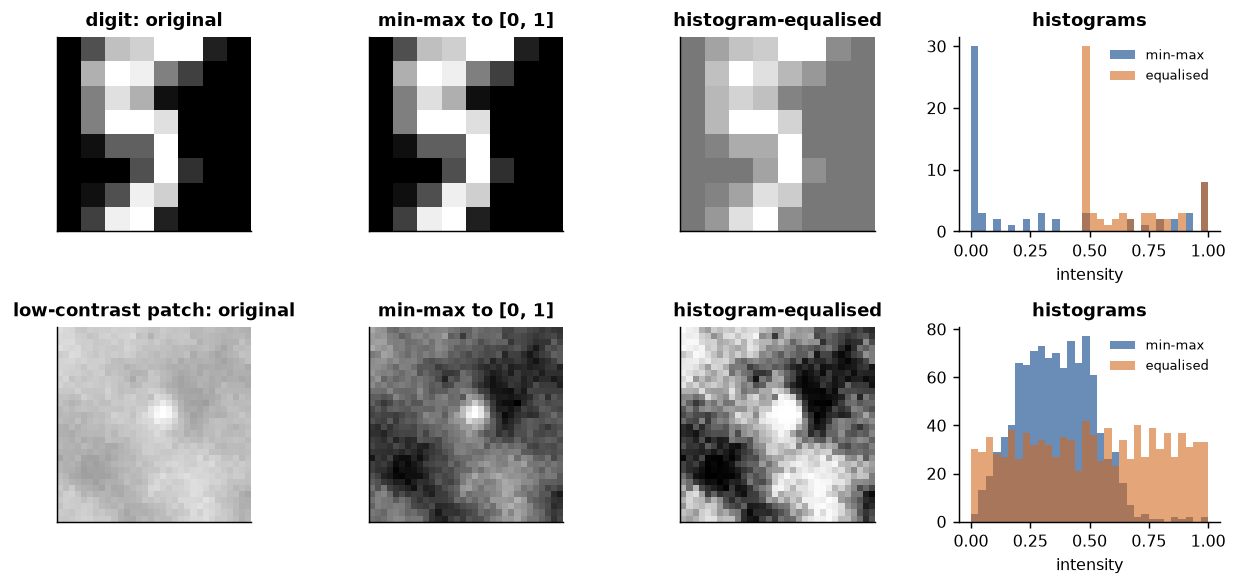

In [5]:
# Normalización de intensidades (min-max, z-score) y ecualización del histograma implementadas en numpy.
def minmax(img):      return (img - img.min()) / (img.max() - img.min() + 1e-12)
def zscore(img):      return (img - img.mean()) / (img.std() + 1e-12)
def equalise(img, levels=256):
    '''Histogram equalisation: map each grey level through the cumulative distribution of the image.'''
    q = np.minimum((minmax(img) * (levels - 1)).round().astype(int), levels - 1)     # cuantiza a L niveles
    cdf = np.cumsum(np.bincount(q.ravel(), minlength=levels)) / q.size              # F(v)
    return cdf[q]                                                                     # en [0, 1]

low = 0.25 + 0.25 * nod_X[nod_y == 1][3]                      # un parche positivo con el contraste reducido a un cuarto
dig = I_dig[15]
print("digit: min %.0f max %.0f mean %.2f sd %.2f | after z-score: mean %.2f sd %.2f" %
       (dig.min(), dig.max(), dig.mean(), dig.std(), zscore(dig).mean(), zscore(dig).std()))
print("low-contrast patch: range [%.3f, %.3f] -> after min-max [%.1f, %.1f] -> after equalisation sd %.3f (was %.3f)" %
       (low.min(), low.max(), minmax(low).min(), minmax(low).max(), equalise(low).std(), low.std()))

fig, axes = plt.subplots(2, 4, figsize=(9.5, 4.6))
for r, (im, name) in enumerate([(dig, "digit"), (low, "low-contrast patch")]):
    panels = [(im, f"{name}: original"), (minmax(im), "min-max to [0, 1]"), (equalise(im), "histogram-equalised")]
    for c, (p, t) in enumerate(panels):
        axes[r, c].imshow(p, vmin=0, vmax=p.max() if c == 0 else 1); axes[r, c].set_title(t); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 3].hist(minmax(im).ravel(), bins=32, range=(0, 1), color="#2b5d9b", alpha=0.7, label="min-max")
    axes[r, 3].hist(equalise(im).ravel(), bins=32, range=(0, 1), color="#d2691e", alpha=0.6, label="equalised")
    axes[r, 3].set_title("histograms"); axes[r, 3].legend(frameon=False, fontsize=7); axes[r, 3].set_xlabel("intensity")
fig.tight_layout()

<p class="caption"><b>Figura 3.</b> Arriba: un dígito; abajo: un parche con nódulo cuyo contraste se redujo artificialmente a un cuarto. El escalamiento min–max (segunda columna) restituye el rango de visualización, pero no la distribución: el histograma del parche (azul, a la derecha) sigue siendo un pico estrecho. La ecualización (tercera columna, histograma naranja) distribuye los niveles de gris de modo que cada uno se use aproximadamente con la misma frecuencia, lo que hace visible el nódulo; en el dígito, donde la mayoría de los píxeles son papel blanco, la ecualización exagera la tinta tenue y no aporta ningún beneficio. La desviación estándar impresa del parche ecualizado es varias veces la del original. La ecualización es una operación global; la versión adaptativa con contraste limitado (CLAHE), aplicada por teselas, es la que se usa en la práctica en radiografías y en el preprocesamiento de los conjuntos de datos de retina y dermatoscopía de la Sección 8.</p>

<div class="box warn"><h4>¿Normalizar por imagen o por conjunto de datos?</h4><p>La normalización por imagen (esta sección) elimina las diferencias de exposición entre imágenes; la estandarización por característica sobre el conjunto de entrenamiento (<code>StandardScaler</code>, Sección 4) pone cada posición de píxel en la misma escala para el optimizador. Son operaciones distintas y normalmente se aplican ambas. Se haga lo que se haga, los parámetros de cualquier normalización <em>a nivel del conjunto de datos</em> —las medias y desviaciones estándar de <code>StandardScaler</code>— deben calcularse solo con los pliegues de entrenamiento y aplicarse al pliegue de prueba, exactamente como exigía el Suplemento S1 para evitar la fuga de datos; el <code>Pipeline</code> usado a lo largo de este notebook lo garantiza.</p></div>

### 2.2 Redimensionamiento y eliminación de ruido

Las redes necesitan entradas de tamaño fijo, y las imágenes llegan con muchos tamaños y espaciados de píxel. El **redimensionamiento** por interpolación (<code>scipy.ndimage.zoom</code>) cambia el número de píxeles; el orden de interpolación importa a baja resolución: el vecino más cercano (orden 0) conserva bloques, mientras que la interpolación lineal (orden 1) y la cúbica (orden 3) producen bordes suaves que nunca se midieron. Reducir el tamaño promediando bloques de píxeles (**submuestreo**, downsampling) es la operación que realizan las capas de pooling en la Sección 6. La **eliminación de ruido** con un filtro gaussiano reemplaza cada píxel por un promedio ponderado de sus vecinos con pesos $\propto \exp(-d^2 / 2\sigma^2)$; es una convolución (Sección 6.2), y su único parámetro $\sigma$ equilibra ruido frente a nitidez. La celda aplica ambas operaciones a un dígito y a un parche al que se le agregó ruido adicional.

mean absolute error vs the clean patch: noisy 0.096 | sigma=0.5: 0.064 sigma=1.0: 0.039 sigma=2.0: 0.046


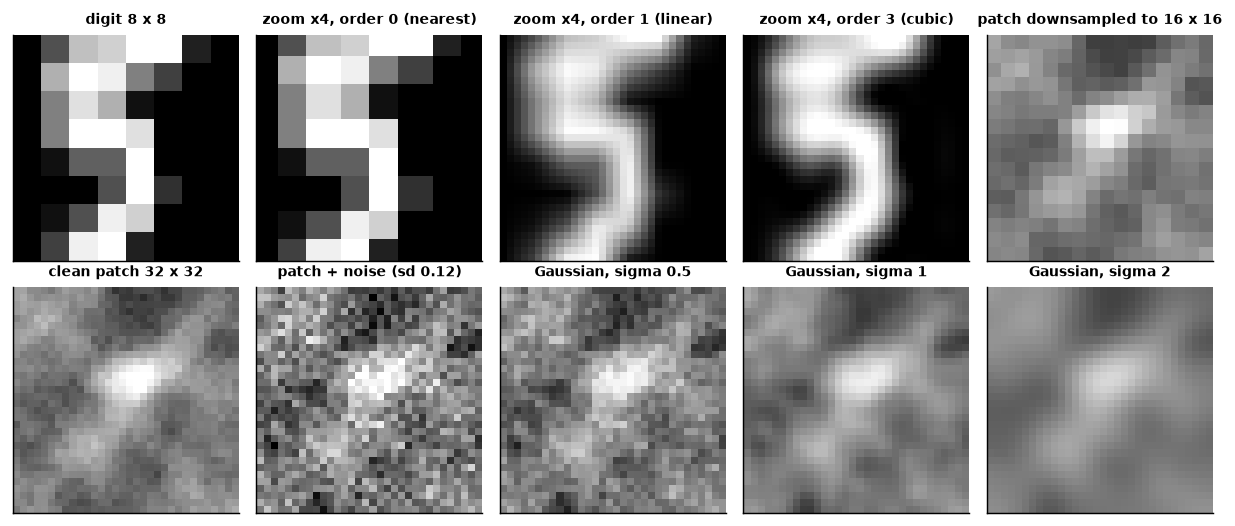

In [6]:
# Redimensionamiento por interpolación, submuestreo por promedio de bloques y eliminación de ruido gaussiana.
rng = np.random.default_rng(2)
patch = nod_X[nod_y == 1][4]                                                    # un parche positivo con un nódulo claro
noisy = np.clip(patch + rng.normal(0, 0.12, patch.shape), 0, 1)
up = {o: ndimage.zoom(dig, 4, order=o) for o in (0, 1, 3)}                    # 8x8 -> 32x32
down16 = patch.reshape(16, 2, 16, 2).mean(axis=(1, 3))                          # 32x32 -> 16x16 por promedio de bloques
blur = {s: ndimage.gaussian_filter(noisy, s) for s in (0.5, 1.0, 2.0)}
err = {s: np.abs(blur[s] - patch).mean() for s in blur}
print("mean absolute error vs the clean patch: noisy %.3f |" % np.abs(noisy - patch).mean(),
      " ".join(f"sigma={s}: {e:.3f}" for s, e in err.items()))

fig, axes = plt.subplots(2, 5, figsize=(9.5, 4.1))
top = [(dig, "digit 8 x 8", 16), (up[0], "zoom x4, order 0 (nearest)", 16), (up[1], "zoom x4, order 1 (linear)", 16), (up[3], "zoom x4, order 3 (cubic)", 16), (down16, "patch downsampled to 16 x 16", 1)]
bottom = [(patch, "clean patch 32 x 32", 1), (noisy, "patch + noise (sd 0.12)", 1), (blur[0.5], "Gaussian, sigma 0.5", 1), (blur[1.0], "Gaussian, sigma 1", 1), (blur[2.0], "Gaussian, sigma 2", 1)]
for row, panels in enumerate((top, bottom)):
    for c, (im, t, vmax) in enumerate(panels):
        axes[row, c].imshow(im, vmin=0, vmax=vmax); axes[row, c].set_title(t, fontsize=8); axes[row, c].set_xticks([]); axes[row, c].set_yticks([])
fig.tight_layout()

<p class="caption"><b>Figura 4.</b> Arriba: el mismo dígito ampliado cuatro veces con tres órdenes de interpolación. La versión de vecino más cercano es honesta respecto de la grilla de ocho por ocho; la versión cúbica parece un trazo suave que nunca se registró. Arriba a la derecha: un parche limpio con nódulo submuestreado a 16 × 16 promediando bloques de 2 × 2 —un cuarto de los píxeles, y el nódulo sigue visible. Abajo: el parche limpio, el mismo parche con mucho ruido agregado, y el parche ruidoso suavizado con filtros gaussianos de ancho creciente. Los errores absolutos medios impresos respecto del parche limpio bajan desde la imagen ruidosa hasta σ = 1 y vuelven a subir en σ = 2, donde el filtro empieza a borrar el propio nódulo: la eliminación de ruido tiene un óptimo, y ese óptimo depende del tamaño de la estructura que se quiere conservar.</p>

### 2.3 Aumento de datos

Un clasificador que ve cada imagen una sola vez, en una sola orientación, aprende la orientación además del patrón. El **aumento de datos** (data augmentation) amplía la muestra con copias transformadas de sus imágenes —volteos, rotaciones, desplazamientos, pequeños cambios de escala y de intensidad— con la condición de que la transformación **preserve la etiqueta**.<sup class="c"><a href="#r12">[12]</a></sup> La condición es todo el método: una radiografía de tórax volteada de izquierda a derecha sigue mostrando neumonía, pero un corazón en espejo es *situs inversus*, un diagnóstico en sí mismo; una imagen dermatoscópica puede rotarse en cualquier ángulo, porque la piel no tiene "arriba"; un 6 manuscrito rotado en 180° es un 9. El aumento de datos también implementa una **invariancia** en la que cree quien diseña el sistema —"la etiqueta no depende de un desplazamiento de un píxel"— y la Sección 6 mide cuánto de esa invariancia adquiere un perceptrón a partir de él.

Label preserved?  digit: flips and 90-degree rotation NO (a flipped or inverted 6 is a 9 or not a digit); small rotation, shift, brightness YES
                  patch: all six YES (a nodule is a nodule in any orientation and exposure)


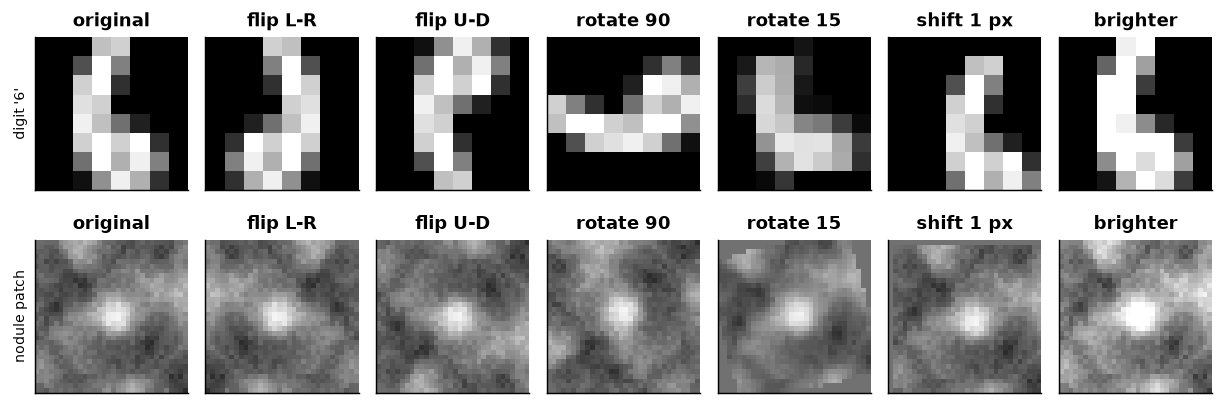

In [7]:
# Aumentos que preservan la etiqueta (y que la destruyen) de un dígito y de un parche.
def augment(im, kind, cval=0.0):
    if kind == "flip L-R":   return im[:, ::-1]
    if kind == "flip U-D":   return im[::-1, :]
    if kind == "rotate 90":  return np.rot90(im)
    if kind == "rotate 15":  return ndimage.rotate(im, 15, reshape=False, order=1, cval=cval)
    if kind == "shift 1 px": return ndimage.shift(im, (1, 1), order=0, cval=cval)
    if kind == "brighter":   return np.clip(im * 1.25, 0, im.max() * 1.25)
kinds = ["flip L-R", "flip U-D", "rotate 90", "rotate 15", "shift 1 px", "brighter"]
six, patch = I_dig[y_dig == 6][0], nod_X[nod_y == 1][1]

fig, axes = plt.subplots(2, 7, figsize=(9.5, 3.4))
for r, (im, vmax) in enumerate([(six, 16), (patch, 1)]):
    axes[r, 0].imshow(im, vmin=0, vmax=vmax); axes[r, 0].set_title("original")
    for c, k in enumerate(kinds, start=1):
        a = augment(im, k, cval=0.0 if vmax == 16 else im.mean()); axes[r, c].imshow(a, vmin=0, vmax=vmax); axes[r, c].set_title(k)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("digit '6'", fontsize=8); axes[1, 0].set_ylabel("nodule patch", fontsize=8)
fig.tight_layout()
print("Label preserved?  digit: flips and 90-degree rotation NO (a flipped or inverted 6 is a 9 or not a digit); small rotation, shift, brightness YES")
print("                  patch: all six YES (a nodule is a nodule in any orientation and exposure)")

<p class="caption"><b>Figura 5.</b> Seis aumentos de un dígito (arriba) y de un parche con nódulo (abajo). Para el parche, toda transformación es admisible: el nódulo sigue siendo un nódulo. Para el dígito, los volteos y el cuarto de vuelta cambian o destruyen la clase, mientras que la rotación pequeña, el desplazamiento y el cambio de brillo no lo hacen. Por lo tanto, el aumento de datos requiere una decisión de alguien que conozca el dominio, y esa es una de las razones por las que un bioingeniero, y no solo un informático, tiene un lugar en un equipo de IA en imágenes. El aumento se aplica solo a los pliegues de entrenamiento; aumentar antes de dividir pondría copias transformadas de una imagen de prueba en el conjunto de entrenamiento, la fuga de datos del Suplemento S1 bajo un nuevo disfraz.</p>

<div class="exercise"><h4>Ejercicio 1</h4><p>En la celda anterior, reemplaza el dígito por un <code>0</code> y por un <code>8</code> y decide, para cada transformación, si la etiqueta se preserva. Luego agrega una transformación propia —una rotación de 180° (<code>np.rot90(im, 2)</code>)— y enumera los dígitos para los cuales preserva la etiqueta. (La respuesta es una lista sorprendentemente corta.)</p></div>

## 3. Características diseñadas a mano frente a características aprendidas

Hasta alrededor de 2012, clasificar imágenes significaba diseñar características: números calculados a partir de la imagen mediante una regla escrita por el ingeniero, sugerida por la descripción que un radiólogo hace de la lesión —"más brillante", "redonda", "textura heterogénea"— y entregados a los clasificadores de las Unidades 3 y 4. Esta sección construye un pequeño extractor de ese tipo, desarrolla a mano su componente de textura y entrena con él k vecinos más cercanos, una máquina de vectores de soporte y un bosque aleatorio: la **línea base clásica** frente a la cual se juzga el perceptrón de la Sección 4.

### 3.1 Características de primer orden

Las características de primer orden dependen solo de la distribución de las intensidades, no de su disposición: la media, la desviación estándar, la asimetría, la curtosis y el rango de los valores de los píxeles, y la **entropía** del histograma, $-\sum_v p(v) \log_2 p(v)$, que mide qué tan dispersos están los niveles de gris. Un nódulo aumenta ligeramente la asimetría (una cola brillante) y el máximo del parche; las características de textura capturan cómo está dispuesto el brillo.

### 3.2 Textura: la matriz de co-ocurrencia de niveles de gris, a mano

La matriz de co-ocurrencia de Haralick (GLCM) es el descriptor de textura clásico, todavía usado en radiómica.<sup class="c"><a href="#r13">[13]</a></sup> Cuantiza la imagen a $L$ niveles de gris, elige un desplazamiento (por ejemplo, "un píxel a la derecha") y cuenta cuántas veces un píxel de nivel $i$ tiene un vecino de nivel $j$ en ese desplazamiento. Los conteos, normalizados para que sumen uno, forman la matriz $L \times L$ $P(i, j)$; a partir de ella se calculan luego características escalares. Tres de las catorce de Haralick bastan para esta unidad:

<div class="eq">$$\text{contrast} = \sum_{i,j} (i - j)^2 P(i,j), \qquad \text{homogeneity} = \sum_{i,j} \frac{P(i,j)}{1 + |i - j|}, \qquad \text{energy} = \sum_{i,j} P(i,j)^2$$
<span class="where">El contraste es grande cuando los píxeles vecinos difieren (bordes, ruido); la homogeneidad es grande cuando se parecen (regiones suaves); la energía es grande cuando unas pocas transiciones dominan (textura regular). Una cuarta característica, la correlación entre $i$ y $j$ bajo $P$, mide la estructura lineal.</span></div>

Toma una imagen de 4 × 4 cuantizada a $L = 4$ niveles y el desplazamiento "un píxel a la derecha":

$$\mathbf{I} = \begin{pmatrix} 0 & 0 & 1 & 1 \\ 0 & 0 & 1 & 1 \\ 0 & 2 & 2 & 2 \\ 2 & 2 & 3 & 3 \end{pmatrix}$$

Cada fila tiene tres pares horizontales $(I_{r,c}, I_{r,c+1})$, doce en total: la fila 1 da (0,0), (0,1), (1,1); la fila 2 lo mismo; la fila 3 da (0,2), (2,2), (2,2); la fila 4 da (2,2), (2,3), (3,3). Contando:

| par $(i,j)$ | (0,0) | (0,1) | (0,2) | (1,1) | (2,2) | (2,3) | (3,3) |
|---|---|---|---|---|---|---|---|
| conteo | 2 | 2 | 1 | 2 | 3 | 1 | 1 |
| $P(i,j)$ | 2/12 | 2/12 | 1/12 | 2/12 | 3/12 | 1/12 | 1/12 |

Entonces, el contraste $= [2 \cdot 1^2 + 1 \cdot 2^2 + 1 \cdot 1^2]/12 = 7/12 \approx 0.583$ (solo contribuyen los pares fuera de la diagonal); la homogeneidad $= [8 \cdot 1 + 2 \cdot \tfrac{1}{2} + 1 \cdot \tfrac{1}{3} + 1 \cdot \tfrac{1}{2}]/12 \approx 0.819$; la energía $= (4 + 4 + 1 + 4 + 9 + 1 + 1)/144 = 24/144 \approx 0.167$. (La definición original de Haralick simetriza la matriz sumándole su transpuesta; la forma no simetrizada que se usa aquí da el mismo contraste y la misma homogeneidad y es más sencilla de seguir.) La celda confirma la aritmética.

In [8]:
# La matriz de co-ocurrencia de niveles de gris y tres características de Haralick, confirmadas con el ejemplo a mano.
def glcm(q, levels, offset=(0, 1)):
    '''Normalised co-occurrence matrix of a quantised image q for a displacement (dy, dx).'''
    dy, dx = offset
    a, b = q[:q.shape[0] - dy, :q.shape[1] - dx].ravel(), q[dy:, dx:].ravel()
    P = np.zeros((levels, levels)); np.add.at(P, (a, b), 1)
    return P / P.sum()

def glcm_features(img, levels=8, offsets=((0, 1), (1, 0))):
    '''Contrast, homogeneity, energy and correlation, averaged over the given displacements.'''
    q = np.minimum((minmax(img) * levels).astype(int), levels - 1)
    i, j = np.indices((levels, levels)); out = []
    for off in offsets:
        P = glcm(q, levels, off); mi, mj = (P * i).sum(), (P * j).sum()
        si, sj = np.sqrt((P * (i - mi) ** 2).sum()), np.sqrt((P * (j - mj) ** 2).sum())
        out.append([(P * (i - j) ** 2).sum(), (P / (1 + np.abs(i - j))).sum(), (P ** 2).sum(),
                    (P * (i - mi) * (j - mj)).sum() / (si * sj + 1e-12)])
    return np.mean(out, axis=0)

I_hand = np.array([[0, 0, 1, 1], [0, 0, 1, 1], [0, 2, 2, 2], [2, 2, 3, 3]])
P = glcm(I_hand, 4, (0, 1))
print("Co-occurrence counts (rows i, columns j), displacement one pixel to the right:\n", (P * 12).astype(int))
i, j = np.indices((4, 4))
print("contrast = %.3f   homogeneity = %.3f   energy = %.3f" % ((P * (i - j) ** 2).sum(), (P / (1 + abs(i - j))).sum(), (P ** 2).sum()))

Co-occurrence counts (rows i, columns j), displacement one pixel to the right:
 [[2 2 1 0]
 [0 2 0 0]
 [0 0 3 1]
 [0 0 0 1]]
contrast = 0.583   homogeneity = 0.819   energy = 0.167


Los conteos y las tres características coinciden con el cálculo a mano: contraste 0.583, homogeneidad 0.819, energía 0.167. La función <code>glcm_features</code> cuantiza una imagen a ocho niveles y promedia las cuatro características sobre los desplazamientos horizontal y vertical, de modo que una textura rotada en un cuarto de vuelta produce los mismos números.

### 3.3 Características de forma a partir de una máscara umbralizada

La forma requiere una **segmentación**: una máscara binaria que indica qué píxeles pertenecen al objeto. La segmentación más simple es un umbral —aquí, los píxeles más brillantes que la media del parche más 1.5 desviaciones estándar tras un suavizado leve— seguido del **etiquetado de componentes conexas** (<code>scipy.ndimage.label</code>), que agrupa los píxeles de primer plano adyacentes en objetos. A partir de la componente más grande calculamos su área, su contraste respecto del fondo y su excentricidad (a partir de los valores propios de la covarianza de las coordenadas de sus píxeles: 0 para un disco, cercana a 1 para una línea); el número de componentes es una cuarta característica que distingue un nódulo de una dispersión de microcalcificaciones. Esta es una miniatura de lo que hizo el programa de Wisconsin con los núcleos celulares en 1993.<sup class="c"><a href="#r9">[9]</a></sup> La celda reúne las catorce características y aplica el extractor a los mil parches de nódulos.

In [9]:
# Un extractor de 14 características diseñadas a mano: 6 de primer orden + 4 de textura + 4 de forma.
def shape_features(img):
    '''Threshold -> connected components -> area, count, eccentricity and contrast of the largest object.'''
    sm = ndimage.gaussian_filter(img, 1.0)
    mask = sm > sm.mean() + 1.5 * sm.std()
    lab, n = ndimage.label(mask)
    if n == 0: return [0.0, 0.0, 0.0, 0.0]
    sizes = ndimage.sum(mask, lab, range(1, n + 1)); k = int(np.argmax(sizes)) + 1
    comp = lab == k; yy, xx = np.nonzero(comp)
    ev = np.sort(np.linalg.eigvalsh(np.cov(np.vstack([xx, yy]))))[::-1] if comp.sum() > 2 else np.ones(2)
    return [float(sizes[k - 1]), float(n), float(np.sqrt(max(1 - ev[1] / (ev[0] + 1e-9), 0))), float(sm[comp].mean() - sm[~mask].mean())]

FEATURE_NAMES = ["mean", "sd", "skewness", "kurtosis", "range", "entropy",
                 "glcm_contrast", "glcm_homogeneity", "glcm_energy", "glcm_correlation", "area", "n_objects", "eccentricity", "obj_contrast"]
def extract_features(img):
    v = img.ravel()
    hist = np.bincount(np.minimum((v * 32).astype(int), 31), minlength=32) / v.size
    first = [v.mean(), v.std(), stats.skew(v), stats.kurtosis(v), v.max() - v.min(), -(hist[hist > 0] * np.log2(hist[hist > 0])).sum()]
    return np.array(first + list(glcm_features(img)) + shape_features(img))

nod_F = np.array([extract_features(im) for im in nod_X])
feat = pd.DataFrame(nod_F, columns=FEATURE_NAMES); feat["label"] = nod_y
print("feature matrix:", nod_F.shape)
feat.groupby("label").mean().T.rename(columns={0: "mean, no lesion", 1: "mean, nodule"}).round(3)

feature matrix: (1000, 14)


label,"mean, no lesion","mean, nodule"
mean,0.450,0.464
sd,0.104,0.117
skewness,0.002,0.408
kurtosis,-0.057,0.850
range,0.615,0.756
entropy,3.760,3.882
glcm_contrast,0.672,0.541
glcm_homogeneity,0.735,0.769
glcm_energy,0.076,0.099
glcm_correlation,0.826,0.834


La tabla de medias por clase ya cuenta una historia. Las características de primer orden apenas se mueven —la intensidad media es casi idéntica en las dos clases, como anticipó la Figura 2—, mientras que las características de forma las separan: los parches positivos tienen un objeto brillante más grande y con mayor contraste respecto de su entorno y, en la GLCM, un contraste menor y una homogeneidad mayor, porque una mancha suave reemplaza parte del fondo moteado. Estos son los números que la descripción de un radiólogo ("una densidad bien circunscrita") habría llevado a un ingeniero a calcular.

### 3.4 La línea base clásica

La celda entrena los tres clasificadores de las Unidades 3–4 —5 vecinos más cercanos, una máquina de vectores de soporte con kernel RBF y un bosque aleatorio de 200 árboles— con las catorce características y, como comparación, con los 1,024 píxeles crudos, usando validación cruzada estratificada de 5 pliegues. Los pliegues quedan fijados por <code>random_state=0</code> y son los mismos para todos los clasificadores, de modo que las diferencias entre filas son diferencias entre métodos y no entre particiones; la Sección 5 hace explícito este diseño pareado.

In [10]:
# Línea base clásica: k-NN, SVM-RBF y bosque aleatorio con características diseñadas a mano y con píxeles crudos.
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
nod_P = nod_X.reshape(len(nod_X), -1)                               # 1000 x 1024 píxeles aplanados
classical = {"k-NN (k = 5)": KNeighborsClassifier(5), "SVM (RBF)": SVC(random_state=0),
             "random forest (200)": RandomForestClassifier(200, random_state=0)}
def cv_summary(model, X, y, cv=cv5):
    s = cross_val_score(make_pipeline(StandardScaler(), model), X, y, cv=cv)
    return s.mean(), s.std()
rows = {}
for name, mdl in classical.items():
    rows[name] = {"14 features": "%.3f ± %.3f" % cv_summary(mdl, nod_F, nod_y), "1,024 pixels": "%.3f ± %.3f" % cv_summary(mdl, nod_P, nod_y)}
baseline = pd.DataFrame(rows).T
print("Nodule task, accuracy (mean ± sd over 5 stratified folds):")
baseline

Nodule task, accuracy (mean ± sd over 5 stratified folds):


,14 features,"1,024 pixels"
k-NN (k = 5),0.872 ± 0.029,0.651 ± 0.036
SVM (RBF),0.898 ± 0.029,0.824 ± 0.018
random forest (200),0.936 ± 0.011,0.895 ± 0.014


Con las catorce características diseñadas, los tres clasificadores alcanzan exactitudes entre aproximadamente 0.87 y 0.94, siendo el bosque aleatorio el mejor de ellos; con los píxeles crudos todos empeoran —el bosque en unos cuatro puntos, la máquina de vectores de soporte en unos siete y k vecinos más cercanos en más de veinte, porque la distancia euclidiana entre vectores de 1,024 píxeles está dominada por la textura de fondo y no por el nódulo. La lección es la misma con la que convivió el campo durante dos décadas: con mil imágenes, *las buenas características superan a los píxeles crudos*, y la calidad del sistema era la calidad de las características del ingeniero. Ten presente la primera columna: es la vara que el perceptrón debe superar.

<div class="box bridge"><h4>Puente hacia la radiómica y hacia BGM324</h4><p>El extractor anterior es una versión de juguete de la <strong>radiómica</strong>, la disciplina que calcula cientos de características estandarizadas de primer orden, de textura y de forma a partir de lesiones segmentadas en CT, MRI y PET, y las entrega a los clasificadores de las Unidades 3–4 para predecir la histología, el estado mutacional o la sobrevida. Sus definiciones de características descienden directamente del artículo de Haralick de 1973.<sup class="c"><a href="#r13">[13]</a></sup> El flujo de trabajo es idéntico al modelado QSAR del curso de bioinformática: un objeto (una lesión, una molécula) se describe mediante un vector de descriptores, y el modelo es tan bueno —y tan reproducible— como lo sean los descriptores.</p></div>

## 4. El perceptrón multicapa como clasificador de imágenes (8.1)

### 4.1 Aplanar, estandarizar, entrenar

La Unidad 6 construyó el perceptrón multicapa: una capa de entrada de $p$ unidades, capas ocultas que calculan $h = \phi(\mathbf{W}\mathbf{x} + \mathbf{b})$ con una activación no lineal $\phi$ (unidad lineal rectificada o función logística) y una capa de salida softmax, ajustado minimizando la función de pérdida de entropía cruzada mediante retropropagación. Nada en esa descripción menciona imágenes: para clasificar una imagen se la aplana (Sección 1.2), se estandariza cada posición de píxel sobre el conjunto de entrenamiento y el resultado se trata como un vector de características de longitud $p = HW$. Para los dígitos, $p = 64$; con una sola capa oculta de $m$ unidades, la red tiene $64m + m$ pesos y sesgos en la primera capa y $10m + 10$ en la capa de salida. La celda construye el modelo como un <code>Pipeline</code> y lo evalúa con la metodología del Suplemento S1 —**validación cruzada estratificada de 5 pliegues repetida**, con dos repeticiones, lo que entrega diez estimaciones de la exactitud de prueba a partir de las cuales se reportan una media y una desviación estándar.

In [11]:
# El perceptrón con dígitos aplanados: número de parámetros y validación cruzada estratificada repetida.
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_predict, train_test_split

def mlp(hidden=(128,), max_iter=200, **kw):
    '''Standardise every pixel position, then a perceptron with the given hidden layers.'''
    return make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=hidden, max_iter=max_iter, random_state=0, **kw))

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=0)       # 10 particiones entrenamiento/prueba, usadas en toda la Sección 5
scores = cross_val_score(mlp((128,)), X_dig, y_dig, cv=rcv)
fitted = mlp((128,)).fit(X_dig, y_dig)                                        # un modelo con todos los datos, para las secciones 4.4 y 6
n_par = sum(w.size for w in fitted[-1].coefs_) + sum(b.size for b in fitted[-1].intercepts_)
print(f"architecture 64 -> 128 -> 10 : {n_par:,} trainable parameters for {len(y_dig):,} images")
print("accuracy per split:", scores.round(3))
print(f"repeated stratified 5-fold CV accuracy: {scores.mean():.3f} ± {scores.std():.3f}   (min {scores.min():.3f}, max {scores.max():.3f})")

architecture 64 -> 128 -> 10 : 9,610 trainable parameters for 1,797 images
accuracy per split: [0.981 0.964 0.981 0.983 0.978 0.986 0.983 0.986 0.975 0.972]
repeated stratified 5-fold CV accuracy: 0.979 ± 0.007   (min 0.964, max 0.986)


El perceptrón clasifica correctamente alrededor del 98 % de los dígitos reservados, con una desviación estándar entre las diez particiones inferior a un punto porcentual. La red tiene más de cinco parámetros por imagen de entrenamiento y aun así generaliza, porque la regla de detención del optimizador, la penalización L2 (<code>alpha</code>) y la suavidad del problema actúan como regularizadores; la Sección 5 varía cada uno de ellos. Observa *para qué* sirve la desviación estándar: una red que obtuviera 0.982 en una sola partición no sería demostrablemente mejor que esta, porque diferencias de ese tamaño en una sola partición ocurren entre repeticiones del mismo modelo.

### 4.2 Qué dígitos se confunden

La exactitud resume; la matriz de confusión (Suplemento S1) explica. La celda obtiene una predicción fuera del pliegue (out-of-fold) para cada imagen con <code>cross_val_predict</code> —cada imagen es predicha por un modelo que no se entrenó con ella— y tabula la clase verdadera frente a la predicha.

out-of-fold accuracy: 0.977 | errors: 41 of 1797
most frequent confusions (true -> predicted : count): 8->1: 4, 9->3: 3, 3->8: 3, 3->5: 3, 8->6: 2, 8->3: 2
per-class recall (sensitivity): {0: 0.994, 1: 0.989, 2: 0.983, 3: 0.945, 4: 0.983, 5: 0.984, 6: 0.983, 7: 0.994, 8: 0.948, 9: 0.967}


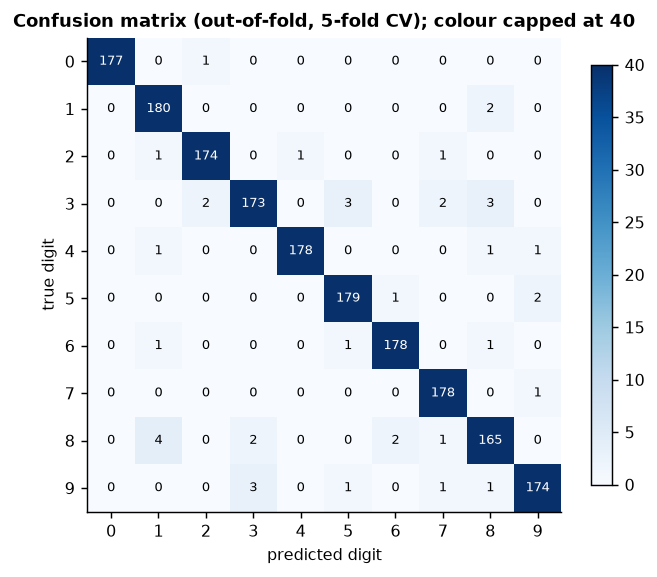

In [12]:
# Predicciones fuera del pliegue y la matriz de confusión de 10 x 10 del clasificador de dígitos.
from sklearn.metrics import confusion_matrix
y_oof = cross_val_predict(mlp((128,)), X_dig, y_dig, cv=cv5)
C = confusion_matrix(y_dig, y_oof)
off = [(C[a, b], a, b) for a in range(10) for b in range(10) if a != b and C[a, b] > 0]
print("out-of-fold accuracy: %.3f | errors: %d of %d" % ((y_oof == y_dig).mean(), (y_oof != y_dig).sum(), len(y_dig)))
print("most frequent confusions (true -> predicted : count):", ", ".join(f"{a}->{b}: {n}" for n, a, b in sorted(off, reverse=True)[:6]))
per_class = pd.Series(np.diag(C) / C.sum(1), index=range(10)).round(3)
print("per-class recall (sensitivity):", per_class.to_dict())

fig, ax = plt.subplots(figsize=(5.2, 4.6))
im = ax.imshow(C, cmap="Blues", vmax=40)                                      # el color se satura en 40 para que las celdas fuera de la diagonal sean visibles
for (a, b), v in np.ndenumerate(C):
    ax.text(b, a, v, ha="center", va="center", fontsize=7, color="white" if v > 25 else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xlabel("predicted digit"); ax.set_ylabel("true digit")
ax.set_title("Confusion matrix (out-of-fold, 5-fold CV); colour capped at 40")
fig.colorbar(im, ax=ax, shrink=0.8); fig.tight_layout()

<p class="caption"><b>Figura 6.</b> La matriz de confusión del perceptrón sobre los 1,797 dígitos, con la escala de color acotada para que los pocos conteos fuera de la diagonal sigan siendo visibles frente a la diagonal (alrededor de 180 por clase). Los errores no se distribuyen de manera uniforme: los pares impresos sobre la figura —formas que comparten trazos, como el 8 con el 1, el 6 o el 3, el 3 con el 8 o el 5, y el 9 con el 3— explican una gran parte de los 41 errores, y la sensibilidad (recall) por clase va desde alrededor de 0.95 (para el 3 y el 8) hasta más de 0.99 (para el 0 y el 7). Un análogo radiológico sería una matriz de confusión de neumonía, edema y atelectasia, tres causas de opacidad que los propios radiólogos confunden; la matriz muestra dónde se necesita un segundo lector.</p>

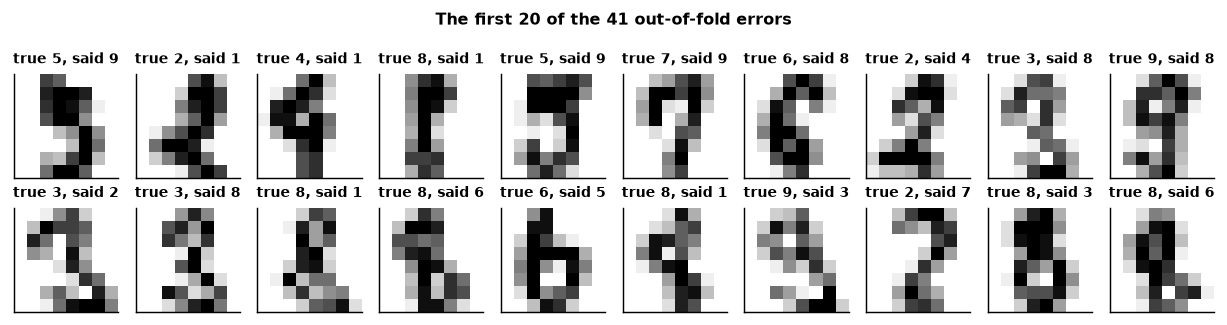

In [13]:
# Los dígitos mal clasificados: en qué se equivocó la red y qué respondió.
wrong = np.where(y_oof != y_dig)[0]
fig, axes = plt.subplots(2, 10, figsize=(9.5, 2.6))
for ax, k in zip(axes.ravel(), wrong[:20]):
    ax.imshow(I_dig[k], cmap="gray_r"); ax.set_title(f"true {y_dig[k]}, said {y_oof[k]}", fontsize=7.5); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"The first 20 of the {len(wrong)} out-of-fold errors", fontsize=9, fontweight="bold")
fig.tight_layout()

<p class="caption"><b>Figura 7.</b> Veinte de los dígitos mal clasificados, con la etiqueta verdadera y la respuesta de la red. Varios son ambiguos incluso para una persona a esta resolución —un 4 o un 8 delgado se lee como un 1, un 5 con el bucle abierto como un 9—, y ese es justamente el punto: con ocho píxeles por lado, a veces la información no está en la imagen, y ningún clasificador puede recuperarla. Mirar los errores es el diagnóstico más barato del campo, y es la etapa en la que se descubrieron, en conjuntos de datos reales, los marcadores de hospital de la Sección 7.</p>

### 4.3 Lo que ha aprendido la primera capa: los pesos como plantillas

Cada unidad oculta de la primera capa calcula $\phi(\mathbf{w}_k^\top \mathbf{x} + b_k)$, una suma ponderada sobre los 64 píxeles. El vector de pesos $\mathbf{w}_k$ tiene una entrada por píxel y, por lo tanto, puede reorganizarse como una imagen de 8 × 8 y mostrarse. Una unidad cuyos pesos son positivos donde se espera tinta y negativos en el resto actúa como una **plantilla** —un filtro adaptado (matched filter) para una configuración de trazos—, exactamente como las plantillas de medias por clase de la Unidad 1, salvo que ahora las plantillas se aprenden para ser *útiles para discriminar* en lugar de ser promedios, y la capa de salida combina 128 de ellas.

weight matrix shape: (64, 128) | weights range [-0.46, 0.40]


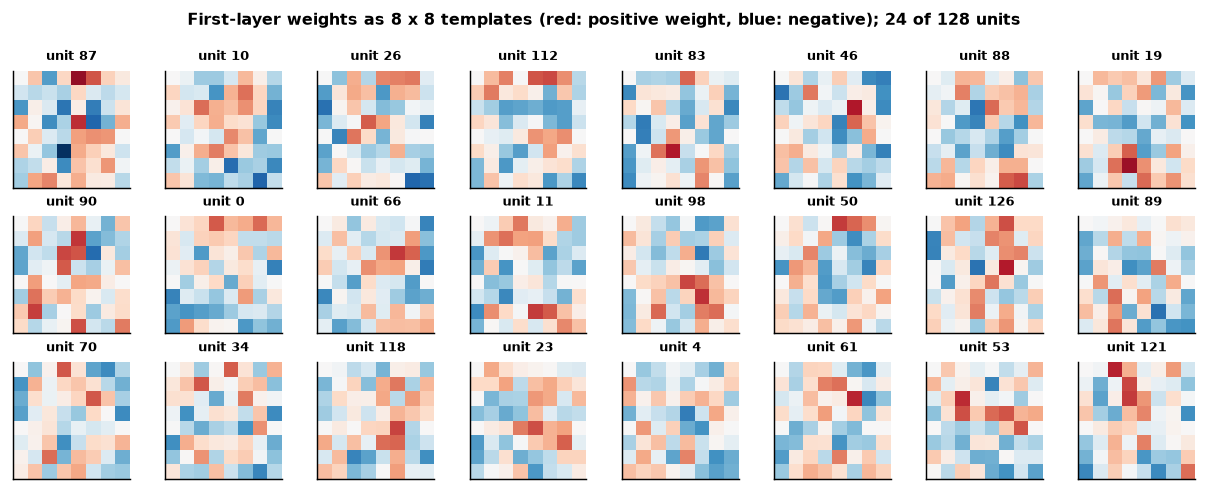

In [14]:
# Pesos de la primera capa del perceptrón de dígitos, reorganizados como imágenes de 8 x 8.
W1 = fitted[-1].coefs_[0]                                                     # (64, 128): una columna por unidad oculta
order = np.argsort(-np.abs(W1).sum(0))[:24]                                   # las 24 unidades con el mayor peso total
vmax = np.abs(W1[:, order]).max()
fig, axes = plt.subplots(3, 8, figsize=(9.5, 3.8))
for ax, k in zip(axes.ravel(), order):
    ax.imshow(W1[:, k].reshape(8, 8), cmap="RdBu_r", vmin=-vmax, vmax=vmax); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"unit {k}", fontsize=7)
fig.suptitle("First-layer weights as 8 x 8 templates (red: positive weight, blue: negative); 24 of 128 units", fontsize=9, fontweight="bold")
fig.tight_layout()
print("weight matrix shape:", W1.shape, "| weights range [%.2f, %.2f]" % (W1.min(), W1.max()))

<p class="caption"><b>Figura 8.</b> Veinticuatro de las 128 unidades de la primera capa, cada una mostrada como la imagen de 8 × 8 de sus pesos. Algunas son detectores de trazos reconocibles —un arco rojo con interior azul responde a un bucle, una barra vertical roja a un trazo vertical— y muchas son combinaciones ruidosas que solo resultan útiles en conjunto con las demás. Las plantillas son <em>globales</em>: cada unidad mira los 64 píxeles con sus propios pesos fijos, de modo que un detector de trazos que se activa ante un bucle en la mitad superior de la imagen es una unidad distinta de otra que detecta el mismo bucle en la mitad inferior. La Sección 6 muestra que esto es exactamente lo que hace al perceptrón frágil ante los desplazamientos y por qué las redes convolucionales comparten pesos entre posiciones.</p>

### 4.4 El perceptrón con los nódulos simulados

La celda repite la comparación de la Sección 3.4 agregando el perceptrón: una vez con los 1,024 píxeles crudos y otra con las 14 características diseñadas. Para el modelo de píxeles, la penalización L2 se eleva a <code>alpha=1</code>, porque con 1,024 entradas y 1,000 imágenes la red sobreajusta severamente con el valor por defecto; esta elección es en sí misma una decisión de topología del tipo que la Sección 5 estudia de forma sistemática.

In [15]:
# El perceptrón en la tarea de nódulos: píxeles crudos frente a características diseñadas a mano, mismos pliegues que la línea base.
mlp_rows = {
    "MLP (64), alpha = 1":    {"14 features": "%.3f ± %.3f" % cv_summary(MLPClassifier((64,), alpha=1.0, max_iter=300, random_state=0), nod_F, nod_y),
                               "1,024 pixels": "%.3f ± %.3f" % cv_summary(MLPClassifier((64,), alpha=1.0, max_iter=300, random_state=0), nod_P, nod_y)},
    "MLP (64), alpha = 1e-4": {"14 features": "%.3f ± %.3f" % cv_summary(MLPClassifier((64,), max_iter=300, random_state=0), nod_F, nod_y),
                               "1,024 pixels": "%.3f ± %.3f" % cv_summary(MLPClassifier((64,), max_iter=300, random_state=0), nod_P, nod_y)},
}
print("Nodule task, accuracy (mean ± sd over the same 5 stratified folds as Section 3.4):")
pd.concat([baseline, pd.DataFrame(mlp_rows).T])

Nodule task, accuracy (mean ± sd over the same 5 stratified folds as Section 3.4):


,14 features,"1,024 pixels"
k-NN (k = 5),0.872 ± 0.029,0.651 ± 0.036
SVM (RBF),0.898 ± 0.029,0.824 ± 0.018
random forest (200),0.936 ± 0.011,0.895 ± 0.014
"MLP (64), alpha = 1",0.923 ± 0.023,0.833 ± 0.017
"MLP (64), alpha = 1e-4",0.918 ± 0.024,0.816 ± 0.017


Con las características diseñadas, el perceptrón se ubica entre la máquina de vectores de soporte y el bosque aleatorio: las características contienen la información, y cualquier clasificador razonable encuentra una frontera. Con los píxeles crudos, el perceptrón con una penalización L2 fuerte alcanza alrededor de 0.83, mucho mejor que k vecinos más cercanos con píxeles y comparable a la máquina de vectores de soporte, pero por debajo del bosque aleatorio con píxeles y **por debajo de todos los modelos basados en características**; sin la penalización es de nuevo ligeramente peor. Este es, en miniatura, el estado del arte de alrededor de 2010: con mil imágenes de entrenamiento, una red poco profunda con píxeles no supera a unas buenas características. La ventaja de las características diseñadas es una ventaja de *conocimiento previo*: alguien sabía que un nódulo es un objeto brillante, redondo y con contraste local, y lo escribió como código. La Sección 6 muestra cómo dar a una red un conocimiento previo comparable sobre las imágenes sin diseñar a mano las características.

### 4.5 Probabilidades y umbrales en un contexto de tamizaje

Un perceptrón entrega una probabilidad $\hat{p}(\text{nodule} \mid \mathbf{x})$; la etiqueta se asigna cuando $\hat{p}$ supera un umbral. El valor por defecto de 0.5 es adecuado cuando ambos errores cuestan lo mismo y la prevalencia de entrenamiento coincide con la del despliegue; ninguna de las dos condiciones se cumple en el tamizaje, donde un cáncer no detectado cuesta más que una nueva citación (recall) y la prevalencia es de unos pocos por ciento. La celda calcula la sensibilidad, la especificidad y la curva ROC (Suplemento S1) a partir de las probabilidades fuera del pliegue y las convierte en valores predictivos positivos a dos prevalencias con el teorema de Bayes (Unidad 3): $\mathrm{PPV} = \frac{\text{se} \cdot \pi}{\text{se} \cdot \pi + (1 - \text{sp})(1 - \pi)}$.

ROC-AUC of the out-of-fold probabilities: 0.916


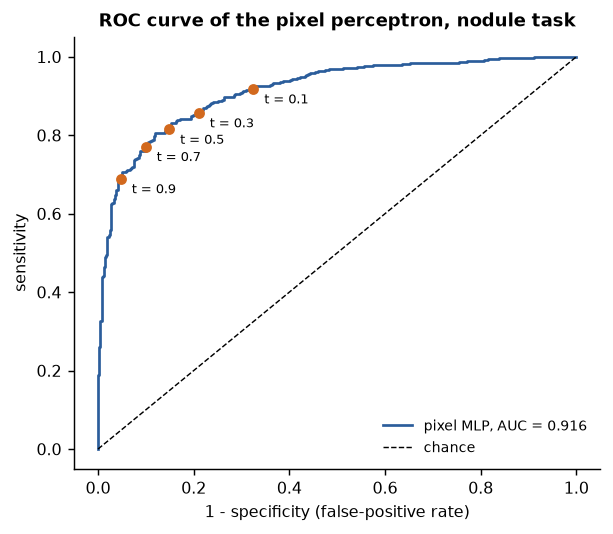

,threshold,sensitivity,specificity,PPV at prevalence 50%,PPV at prevalence 2%
0,0.1,0.918,0.675,0.738,0.054
1,0.3,0.857,0.789,0.802,0.077
2,0.5,0.815,0.851,0.846,0.101
3,0.7,0.771,0.900,0.885,0.135
4,0.9,0.689,0.952,0.935,0.226


In [16]:
# Probabilidades fuera del pliegue, curva ROC y puntos de operación para un contexto de tamizaje.
from sklearn.metrics import roc_curve, roc_auc_score
p_oof = cross_val_predict(make_pipeline(StandardScaler(), MLPClassifier((64,), alpha=1.0, max_iter=300, random_state=0)),
                          nod_P, nod_y, cv=cv5, method="predict_proba")[:, 1]
fpr, tpr, thr = roc_curve(nod_y, p_oof)
rows = []
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred = p_oof >= t
    se = (pred & (nod_y == 1)).sum() / (nod_y == 1).sum(); sp = (~pred & (nod_y == 0)).sum() / (nod_y == 0).sum()
    ppv = lambda pi: se * pi / (se * pi + (1 - sp) * (1 - pi))
    rows.append({"threshold": t, "sensitivity": se, "specificity": sp, "PPV at prevalence 50%": ppv(0.5), "PPV at prevalence 2%": ppv(0.02)})
ops = pd.DataFrame(rows).round(3)
print(f"ROC-AUC of the out-of-fold probabilities: {roc_auc_score(nod_y, p_oof):.3f}")

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.plot(fpr, tpr, color="#2b5d9b", label=f"pixel MLP, AUC = {roc_auc_score(nod_y, p_oof):.3f}")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="chance")
for _, r in ops.iterrows():
    ax.plot(1 - r.specificity, r.sensitivity, "o", color="#d2691e", ms=5); ax.annotate(f"t = {r.threshold}", (1 - r.specificity, r.sensitivity), xytext=(6, -8), textcoords="offset points", fontsize=7)
ax.set_xlabel("1 - specificity (false-positive rate)"); ax.set_ylabel("sensitivity"); ax.set_title("ROC curve of the pixel perceptron, nodule task"); ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
ops

<p class="caption"><b>Figura 9.</b> La curva ROC del perceptrón de píxeles en la tarea de nódulos, construida a partir de probabilidades fuera del pliegue, con cinco umbrales marcados. Bajar el umbral de 0.5 a 0.1 desplaza el punto de operación hacia arriba y hacia la derecha: la sensibilidad sube y la especificidad baja, como muestra la tabla. Las dos últimas columnas son la consecuencia de la prevalencia que se derivó en la Unidad 3: con la prevalencia del 50 % de este conjunto de datos balanceado, el valor predictivo positivo es alto en todos los umbrales, pero con una prevalencia de tamizaje del 2 % la mayoría de los positivos son falsos en cualquier umbral, porque la tasa de falsos positivos se aplica a la gran mayoría sana. La curva y su AUC son propiedades del modelo; el PPV es una propiedad del modelo <em>y</em> de la población, y una herramienta de tamizaje debe evaluarse con la prevalencia en la que se usará.</p>

<div class="exercise"><h4>Ejercicio 2</h4><p>Elige el umbral que da una sensibilidad de al menos 0.95 (interpola a partir de <code>fpr, tpr, thr</code>) y calcula el número de falsos positivos por cada 1,000 pacientes tamizados con una prevalencia del 2 %. Luego repite con el bosque aleatorio basado en características de la Sección 3.4 (usa <code>method="predict_proba"</code>). ¿Qué modelo desplegarías como <em>segundo lector</em>, cuyos positivos revisa un radiólogo, y cuál como herramienta de <em>triaje</em> que descarta los negativos sin que nadie los lea?</p></div>

## 5. Pruebas experimentales de la topología de la red (8.2)

### 5.1 Cómo realizar un experimento honesto

La topología de un perceptrón —capas ocultas, unidades por capa, activación, intensidad de la regularización, optimizador, tasa de aprendizaje, tamaño de lote, regla de detención— no se aprende de los datos; la elige el ingeniero, y el programa del curso te pide elegirla *experimentalmente*. Cuatro reglas, todas del Suplemento S1, hacen que un experimento así sea confiable:

1. **Las mismas particiones para todas las configuraciones** (el <code>RepeatedStratifiedKFold</code> fijado por <code>random_state=0</code>), de modo que las diferencias entre configuraciones no se confundan con diferencias entre particiones: la comparación es *pareada*.
2. **Repite, y reporta la varianza.** Una diferencia menor que las desviaciones estándar entre particiones no es un hallazgo.
3. **Cambia un factor a la vez**, o cruza los factores en un diseño factorial, como en la grilla profundidad × ancho de más abajo.
4. **No reportes el mejor puntaje de validación cruzada como el rendimiento esperado.** Elegir la mejor de muchas configuraciones con los mismos pliegues ajusta esos pliegues, y el puntaje elegido está sesgado de forma optimista;<sup class="c"><a href="#r15">[15]</a></sup> la Sección 5.6 muestra el remedio.

### 5.2 Profundidad × ancho

El primer experimento cruza el número de capas ocultas (0, 1, 2, 3) con el número de unidades por capa (8, 32, 128) en los dígitos. Una red con cero capas ocultas es una regresión logística multinomial entrenada con el mismo optimizador: la línea base lineal. Las diez particiones toman unos pocos segundos por configuración, por lo que la grilla se calcula en tres celdas.

In [17]:
# Grilla profundidad x ancho, parte 1: cero y una capa oculta, CV estratificada de 5 pliegues repetida (10 particiones cada una).
def topology_score(hidden, **kw):
    '''Accuracy on the 10 fixed splits of rcv for a perceptron with the given hidden layers.'''
    return cross_val_score(mlp(hidden, **kw), X_dig, y_dig, cv=rcv)

grid = {}
grid[(0, "-")] = topology_score(())                                             # sin capa oculta: regresión softmax
for w in (8, 32, 128):
    grid[(1, w)] = topology_score((w,))
for (d, w), s in grid.items():
    print(f"depth {d}, width {w!s:>3}:  {s.mean():.4f} ± {s.std():.4f}")

depth 0, width   -:  0.9566 ± 0.0085
depth 1, width   8:  0.9332 ± 0.0114
depth 1, width  32:  0.9719 ± 0.0090
depth 1, width 128:  0.9789 ± 0.0066


In [18]:
# Grilla profundidad x ancho, parte 2: dos capas ocultas.
for w in (8, 32, 128):
    grid[(2, w)] = topology_score((w, w))
    print(f"depth 2, width {w:>3}:  {grid[(2, w)].mean():.4f} ± {grid[(2, w)].std():.4f}")

depth 2, width   8:  0.9346 ± 0.0151
depth 2, width  32:  0.9652 ± 0.0095
depth 2, width 128:  0.9761 ± 0.0066


depth 3, width   8:  0.9165 ± 0.0132
depth 3, width  32:  0.9563 ± 0.0105
depth 3, width 128:  0.9769 ± 0.0048
best configuration: depth 1, width 128 -> 0.9789; linear baseline (depth 0): 0.9566


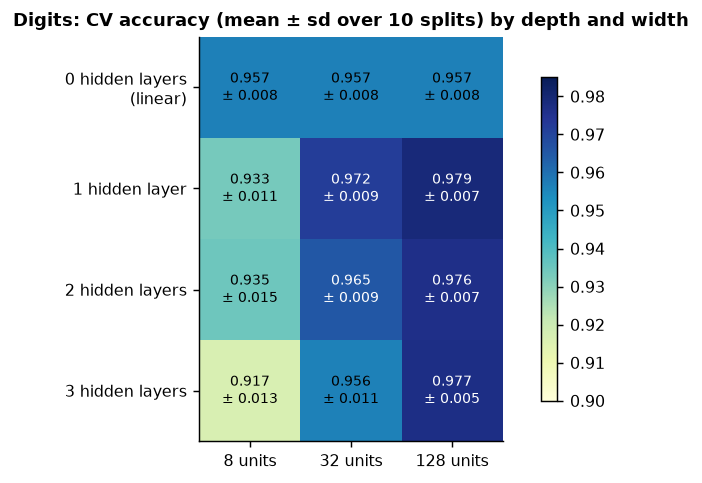

In [19]:
# Grilla profundidad x ancho, parte 3: tres capas ocultas; luego la tabla completa y un mapa de calor.
for w in (8, 32, 128):
    grid[(3, w)] = topology_score((w, w, w))
    print(f"depth 3, width {w:>3}:  {grid[(3, w)].mean():.4f} ± {grid[(3, w)].std():.4f}")

M, S = np.zeros((4, 3)), np.zeros((4, 3))
for (d, w), s in grid.items():
    for j in (range(3) if w == "-" else [[8, 32, 128].index(w)]):       # el modelo lineal llena toda su fila
        M[d, j], S[d, j] = s.mean(), s.std()
best = max(grid, key=lambda k: grid[k].mean())
print(f"best configuration: depth {best[0]}, width {best[1]} -> {grid[best].mean():.4f}; "
      f"linear baseline (depth 0): {grid[(0, '-')].mean():.4f}")
fig, ax = plt.subplots(figsize=(6.2, 3.8))
im = ax.imshow(M, cmap="YlGnBu", vmin=0.90, vmax=0.985)
for (d, j), v in np.ndenumerate(M):
    ax.text(j, d, f"{v:.3f}\n± {S[d, j]:.3f}", ha="center", va="center", fontsize=8, color="white" if v > 0.965 else "black")
ax.set_xticks(range(3)); ax.set_xticklabels(["8 units", "32 units", "128 units"]); ax.set_yticks(range(4)); ax.set_yticklabels(["0 hidden layers\n(linear)", "1 hidden layer", "2 hidden layers", "3 hidden layers"])
ax.set_title("Digits: CV accuracy (mean ± sd over 10 splits) by depth and width"); fig.colorbar(im, ax=ax, shrink=0.8); fig.tight_layout()

<p class="caption"><b>Figura 10.</b> La grilla profundidad × ancho en los dígitos (el modelo lineal no tiene ancho y se repite a lo largo de su fila). Tres observaciones. Primero, el ancho importa más que la profundidad: en todas las profundidades, las redes de 128 unidades son las mejores y las de 8 unidades son las peores —peores, en todas las profundidades, que el modelo lineal—, porque un cuello de botella de ocho unidades no puede transportar la información que requieren diez clases. Segundo, la profundidad no ayuda aquí: la mejor red tiene una sola capa oculta, y apilar dos o tres capas de 128 unidades no la mejora; con ancho 32 cada capa agregada reduce la exactitud, y con ancho 8 tres capas son peores que una. Tercero, las diferencias entre las tres redes de 128 unidades son menores que sus desviaciones estándar, de modo que el experimento no las ordena: dice que son equivalentes con 1,797 imágenes. "Más grande es mejor" es un eslogan sobre redes entrenadas con millones de imágenes; con una muestra pequeña, la capacidad que los datos no pueden restringir se desperdicia o resulta dañina, y el reporte honesto es la grilla completa con sus barras de error, no la mejor celda.</p>

### 5.3 Curvas de aprendizaje: cómo depende el rendimiento de la muestra

Una curva de aprendizaje grafica la exactitud de validación cruzada frente al número de imágenes de entrenamiento. Responde la pregunta que la grilla no puede responder: *¿ayudarían más datos, y qué modelo se beneficiaría?* La celda dibuja las curvas de la red de una sola capa más pequeña y de la más grande, junto con la exactitud de entrenamiento.

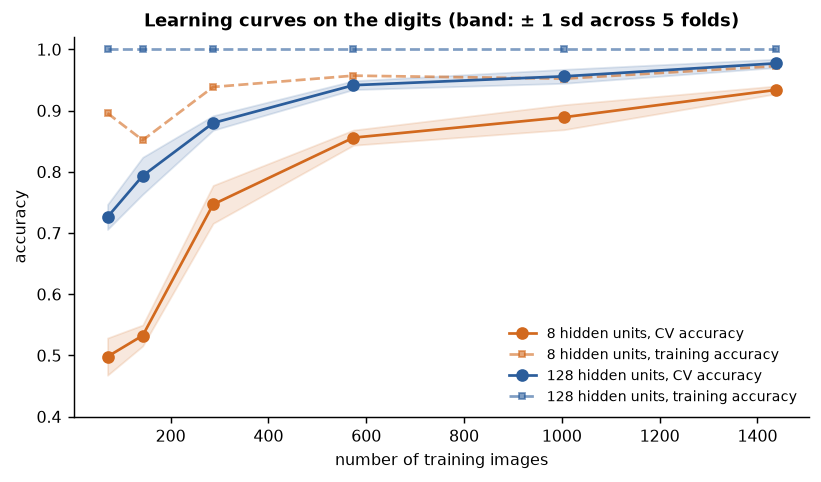

,n = 71,n = 143,n = 287,n = 574,n = 1005,n = 1437
"8 units, CV",0.498,0.533,0.747,0.856,0.889,0.934
"8 units, training",0.896,0.852,0.939,0.957,0.952,0.973
"128 units, CV",0.726,0.794,0.880,0.942,0.956,0.977
"128 units, training",1.000,1.000,1.000,1.000,1.000,1.000


In [20]:
# Curvas de aprendizaje de un perceptrón angosto y de uno ancho: exactitud de entrenamiento y de CV frente al tamaño del conjunto de entrenamiento.
from sklearn.model_selection import learning_curve
fig, ax = plt.subplots(figsize=(6.4, 3.8))
summary = {}
for hidden, col in [((8,), "#d2691e"), ((128,), "#2b5d9b")]:
    sizes, tr, te = learning_curve(mlp(hidden), X_dig, y_dig, train_sizes=[0.05, 0.1, 0.2, 0.4, 0.7, 1.0], cv=cv5, random_state=0)
    ax.plot(sizes, te.mean(1), "o-", color=col, label=f"{hidden[0]} hidden units, CV accuracy")
    ax.fill_between(sizes, te.mean(1) - te.std(1), te.mean(1) + te.std(1), color=col, alpha=0.15)
    ax.plot(sizes, tr.mean(1), "s--", color=col, alpha=0.6, ms=3, label=f"{hidden[0]} hidden units, training accuracy")
    summary[f"{hidden[0]} units, CV"] = dict(zip(sizes, te.mean(1).round(3))); summary[f"{hidden[0]} units, training"] = dict(zip(sizes, tr.mean(1).round(3)))
ax.set_xlabel("number of training images"); ax.set_ylabel("accuracy"); ax.set_ylim(0.4, 1.02)
ax.legend(frameon=False, fontsize=7.5, loc="lower right"); ax.set_title("Learning curves on the digits (band: ± 1 sd across 5 folds)")
fig.tight_layout()
pd.DataFrame(summary).T.rename(columns=lambda c: f"n = {c}")

<p class="caption"><b>Figura 11.</b> Curvas de aprendizaje de los perceptrones de 8 unidades (naranja) y de 128 unidades (azul). La red ancha es mejor con todos los tamaños de muestra y sigue mejorando con 1,437 imágenes de entrenamiento; su exactitud de entrenamiento (línea discontinua, y la segunda fila de la tabla) se mantiene en 1.0 o cerca de ese valor, de modo que la brecha entre las líneas azules discontinua y continua —el sobreajuste— solo se cierra a medida que crece la muestra. La red angosta se estanca más abajo y su exactitud de entrenamiento tampoco llega a 1.0 con los tamaños mayores: está limitada por su propia capacidad (subajuste), y más datos la ayudarían poco. Estas curvas son el diagnóstico estándar para decidir si conviene reunir más imágenes —lo que en imágenes médicas cuesta meses y aprobaciones éticas— o cambiar el modelo.</p>

### 5.4 Activación, detención temprana y regularización

Se varían otros tres factores, uno a la vez, en la red de 128 unidades, con los cinco pliegues estratificados de la Sección 3.4 (cinco particiones en lugar de diez, para que la celda sea rápida). La **activación** es la unidad lineal rectificada o la sigmoide logística, que se satura con entradas grandes y hace más lento el entrenamiento, la razón principal por la que las redes profundas la abandonaron. La **detención temprana** (early stopping) reserva el 10 % de cada pliegue de entrenamiento y se detiene cuando el puntaje de validación no ha mejorado durante diez épocas: un regularizador que cuesta datos de entrenamiento. La **penalización L2** <code>alpha</code> contrae los pesos hacia cero, el equivalente en el perceptrón de la penalización ridge de la Unidad 2, y se varía en seis órdenes de magnitud.

activation  early stopping CV accuracy (5 folds)
      relu           False       0.9772 ± 0.0069
  logistic           False       0.9716 ± 0.0087
      relu            True       0.9594 ± 0.0150 

CV accuracy by alpha: {0.0001: np.float64(0.9772), 0.01: np.float64(0.9772), 1: np.float64(0.9772), 10: np.float64(0.9466), 100: np.float64(0.2966)}


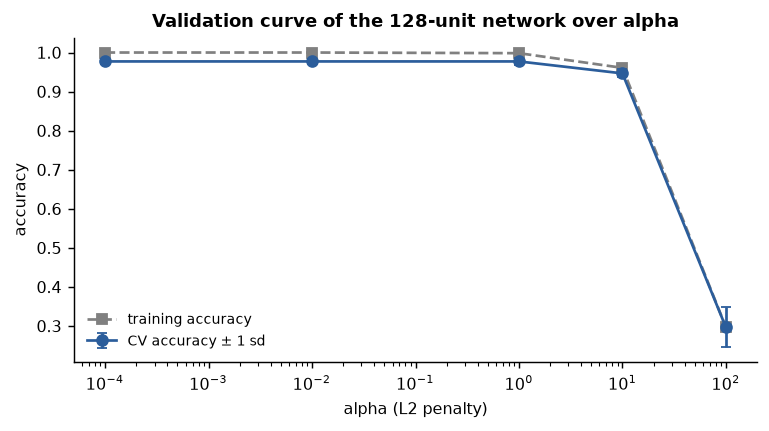

In [21]:
# Activación y detención temprana en la red de 128 unidades; luego una curva de validación sobre alpha (5 pliegues estratificados cada una).
from sklearn.model_selection import validation_curve
rows = []
for act, es in [("relu", False), ("logistic", False), ("relu", True)]:
    s = cross_val_score(mlp((128,), activation=act, early_stopping=es), X_dig, y_dig, cv=cv5)
    rows.append({"activation": act, "early stopping": es, "CV accuracy (5 folds)": f"{s.mean():.4f} ± {s.std():.4f}"})
print(pd.DataFrame(rows).to_string(index=False), "\n")
alphas = [1e-4, 1e-2, 1, 10, 100]
tr, te = validation_curve(mlp((128,)), X_dig, y_dig, param_name="mlpclassifier__alpha", param_range=alphas, cv=cv5)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.semilogx(alphas, tr.mean(1), "s--", color="grey", label="training accuracy")
ax.errorbar(alphas, te.mean(1), yerr=te.std(1), fmt="o-", color="#2b5d9b", capsize=3, label="CV accuracy ± 1 sd")
ax.set_xlabel("alpha (L2 penalty)"); ax.set_ylabel("accuracy"); ax.set_title("Validation curve of the 128-unit network over alpha"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
print("CV accuracy by alpha:", {a: round(m, 4) for a, m in zip(alphas, te.mean(1))})

<p class="caption"><b>Figura 12.</b> Exactitud de entrenamiento (gris) y de validación cruzada (azul) a medida que crece la penalización L2. La curva es plana desde <code>alpha = 1e-4</code> hasta 1 —en los dígitos a la red no le falta regularización—, luego cae en 10 y colapsa en 100, donde la penalización contrae hacia cero las plantillas de la Figura 8 y la exactitud de entrenamiento cae con ellas. La tabla de activaciones anterior muestra a la unidad lineal rectificada ligeramente por delante de la función logística con estos datos, y a la detención temprana costando más de un punto porcentual, porque entrena con el 90 % de cada pliegue y se detiene según una señal de validación ruidosa; con un conjunto de datos más grande y más ruidoso el orden puede invertirse, y por eso estos son experimentos y no reglas.</p>

### 5.5 Optimizador, tasa de aprendizaje y tamaño de lote

Los pesos se ajustan mediante descenso de gradiente estocástico (Unidades 2 y 6): un **minilote** (mini-batch) de imágenes se pasa por la red, el gradiente de la pérdida se calcula por retropropagación y los pesos se mueven en sentido contrario con un paso proporcional a la **tasa de aprendizaje**; <code>adam</code> adapta el paso para cada parámetro a partir de promedios móviles del gradiente, y el <code>sgd</code> simple no lo hace. Una tasa de aprendizaje demasiado pequeña hace lento el entrenamiento, y una demasiado grande hace que la pérdida oscile o diverja; un lote demasiado pequeño hace ruidoso el gradiente, y uno demasiado grande encarece cada época. La celda entrena una red de 64 unidades durante 40 épocas en una sola partición 70/30 con varias configuraciones y grafica la pérdida de entrenamiento por época —la **curva de pérdida**, lo primero que hay que mirar cuando el entrenamiento se comporta mal.

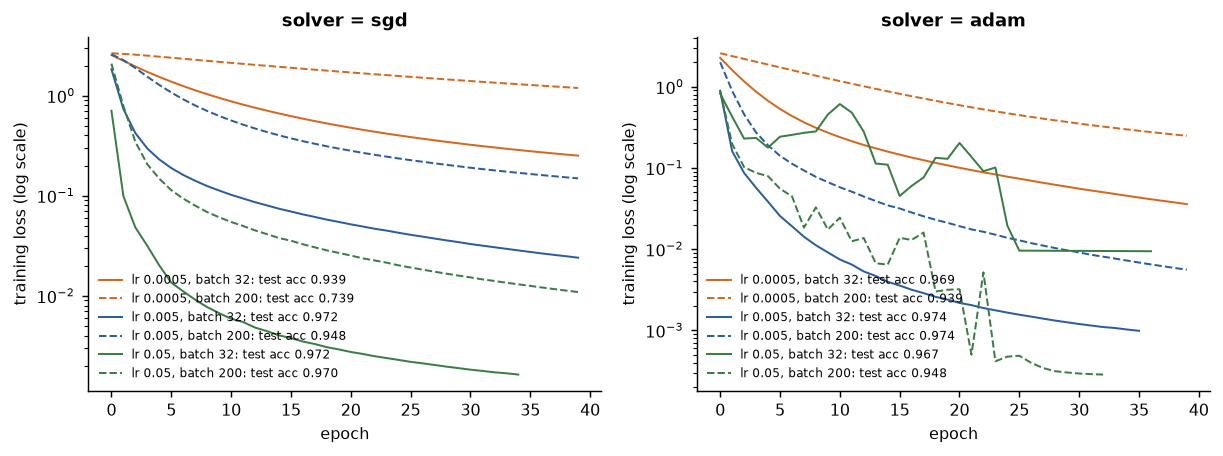

In [22]:
# Curvas de pérdida para dos optimizadores, tres tasas de aprendizaje y tres tamaños de lote (una sola partición 70/30).
Xtr, Xte, ytr, yte = train_test_split(X_dig, y_dig, test_size=0.3, random_state=0, stratify=y_dig)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
for solver, ax in zip(("sgd", "adam"), axes):
    for lr, col in zip((0.0005, 0.005, 0.05), ("#d2691e", "#2b5d9b", "#3a7d44")):
        for bs, ls in zip((32, 200), ("-", "--")):
            m = mlp((64,), solver=solver, learning_rate_init=lr, batch_size=bs, max_iter=40).fit(Xtr, ytr)
            ax.plot(m[-1].loss_curve_, color=col, ls=ls, lw=1.1, label=f"lr {lr}, batch {bs}: test acc {m.score(Xte, yte):.3f}")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("training loss (log scale)"); ax.set_title(f"solver = {solver}")
    ax.legend(frameon=False, fontsize=6.5)
fig.tight_layout()

<p class="caption"><b>Figura 13.</b> Pérdida de entrenamiento por época para el descenso de gradiente estocástico simple (izquierda) y Adam (derecha), con tres tasas de aprendizaje (colores) y dos tamaños de lote (continua: 32 imágenes por lote; discontinua: 200), con la exactitud de prueba tras 40 épocas en cada entrada de la leyenda. Con <code>sgd</code>, la tasa de aprendizaje más pequeña apenas ha comenzado a converger después de 40 épocas y la más grande converge más rápido; los lotes pequeños alcanzan una pérdida menor por época porque dan más pasos. Adam alcanza una pérdida menor que el descenso de gradiente simple con todas las tasas de aprendizaje, y con la tasa más grande su pérdida oscila en un orden de magnitud de una época a otra: la firma característica de un paso demasiado largo. Las exactitudes de prueba difieren en unos pocos puntos a lo largo del panel, lo que es comparable a las diferencias en la grilla de topología: cómo se <em>entrena</em> una red importa tanto como la <em>forma</em> que tiene, y un artículo que reporta una arquitectura sin la configuración de su optimizador no ha descrito un experimento reproducible.</p>

### 5.6 Validación cruzada anidada: elegir la topología sin favorecerla

Si la mejor celda de la grilla de la Sección 5.2 se reporta como "la exactitud de nuestro perceptrón", el número está sesgado hacia arriba: se seleccionó *porque* era la más alta entre doce estimaciones ruidosas en esos mismos pliegues. Varma y Simon midieron este sesgo en conjuntos de datos biomédicos pequeños y encontraron que puede superar las diferencias reales entre métodos.<sup class="c"><a href="#r15">[15]</a></sup> El remedio es la **validación cruzada anidada**: un ciclo *externo* reserva un pliegue de prueba; dentro de cada pliegue de entrenamiento, una validación cruzada *interna* elige la topología (aquí, el ancho de una sola capa oculta); el modelo elegido se vuelve a ajustar con todo el pliegue de entrenamiento y se evalúa una sola vez en el pliegue de prueba externo. Los puntajes externos estiman el rendimiento del *procedimiento* "elegir el ancho por validación cruzada y entrenar", que es lo que realmente se desplegará. La celda lo ejecuta con <code>GridSearchCV</code> como ciclo interno.

In [23]:
# Validación cruzada anidada: grilla interna de 3 pliegues sobre el ancho oculto, estimación externa de 5 pliegues de todo el procedimiento.
from sklearn.model_selection import GridSearchCV
inner = GridSearchCV(mlp(), {"mlpclassifier__hidden_layer_sizes": [(8,), (32,), (128,)]},
                     cv=StratifiedKFold(3, shuffle=True, random_state=1))
nested = cross_val_score(inner, X_dig, y_dig, cv=cv5)
chosen = [inner.fit(X_dig[tr], y_dig[tr]).best_params_["mlpclassifier__hidden_layer_sizes"][0] for tr, _ in cv5.split(X_dig, y_dig)]
naive_best = max(s.mean() for (d, w), s in grid.items() if d == 1)
print(f"nested CV accuracy of 'choose width by inner CV, then train': {nested.mean():.4f} ± {nested.std():.4f}")
print("width chosen in each outer fold:", chosen)
print(f"for comparison, the best single-layer cell of the grid (selected on the same data): {naive_best:.4f}")

nested CV accuracy of 'choose width by inner CV, then train': 0.9761 ± 0.0067
width chosen in each outer fold: [128, 128, 32, 128, 128]
for comparison, the best single-layer cell of the grid (selected on the same data): 0.9789


El ciclo interno eligió la red más ancha en cuatro de los cinco pliegues externos y la red de 32 unidades en el quinto —la elección es bastante estable—, y la estimación anidada está cerca de la mejor celda de la grilla, ligeramente por debajo. La brecha es pequeña aquí porque la grilla era pequeña (tres candidatos) y la señal fuerte; en un conjunto de datos de unos pocos cientos de pacientes con una grilla de cincuenta configuraciones, la brecha es habitualmente de varios puntos porcentuales, y es la diferencia entre una exactitud publicada y la exactitud que observará un hospital. El principio es el del Suplemento S1 llevado un nivel más arriba: todo lo que se *elige* usando datos debe elegirse dentro del ciclo que *evalúa*.

<div class="box key"><h4>Lo que establecieron los experimentos de topología</h4>
<ul>
<li>Con 1,797 imágenes pequeñas, una sola capa oculta ancha es tan buena como cualquier perceptrón más profundo; la profundidad sin datos no ayuda y, con capas angostas, perjudica.</li>
<li>Toda comparación necesita las mismas particiones, repetición y una desviación estándar; la mayoría de las diferencias de esta sección están a menos de una desviación estándar entre sí.</li>
<li>El optimizador, la tasa de aprendizaje, el tamaño de lote, la penalización y la regla de detención cambian el resultado tanto como la arquitectura, y deben reportarse junto con ella.</li>
<li>La configuración se elige mediante validación cruzada interna y el rendimiento se estima mediante validación cruzada externa; la mejor celda de una grilla no es una estimación de nada.</li>
</ul></div>

<div class="exercise"><h4>Ejercicio 3</h4><p>Agrega el ancho 512 a la grilla de la Sección 5.2 (solo con una y dos capas ocultas, para ahorrar tiempo) y a la grilla interna de la validación cruzada anidada. ¿Mejora la red más ancha la estimación anidada? Luego reduce el conjunto de datos a los primeros 400 dígitos (<code>X_dig[:400], y_dig[:400]</code>) y vuelve a ejecutar la fila de una capa oculta de la grilla. ¿Qué ancho gana ahora, y qué tan grandes son las desviaciones estándar?</p></div>

## 6. Invariancia a la traslación, convolución y por qué el perceptrón tiene la forma equivocada para las imágenes

### 6.1 Desplaza un dígito en un píxel

Una unidad de la primera capa de un perceptrón multiplica cada píxel por su propio peso (Figura 8). Si la imagen se desplaza en un píxel, cada píxel se encuentra ahora con el peso destinado a su vecino, y la respuesta de la unidad cambia por completo, aunque la imagen sea "la misma" para cualquier observador. La propiedad que debería tener un clasificador de imágenes —la clase no cambia cuando el objeto se mueve— se llama **invariancia a la traslación**, y un perceptrón no tiene nada de ella salvo lo que aprende, posición por posición, de la muestra de entrenamiento. La celda mide el efecto: la red se entrena con dígitos rellenados hasta 12 × 12 (para que un dígito desplazado no quede cortado) y se prueba con los mismos dígitos reservados desplazados en uno, dos y tres píxeles.

test accuracy of the perceptron when the test digits are shifted by (dx, dy) pixels:
(0, 0): 0.978   (1, 0): 0.409   (0, 1): 0.426   (1, 1): 0.154   (2, 0): 0.170   (2, 2): 0.054   (3, 0): 0.106


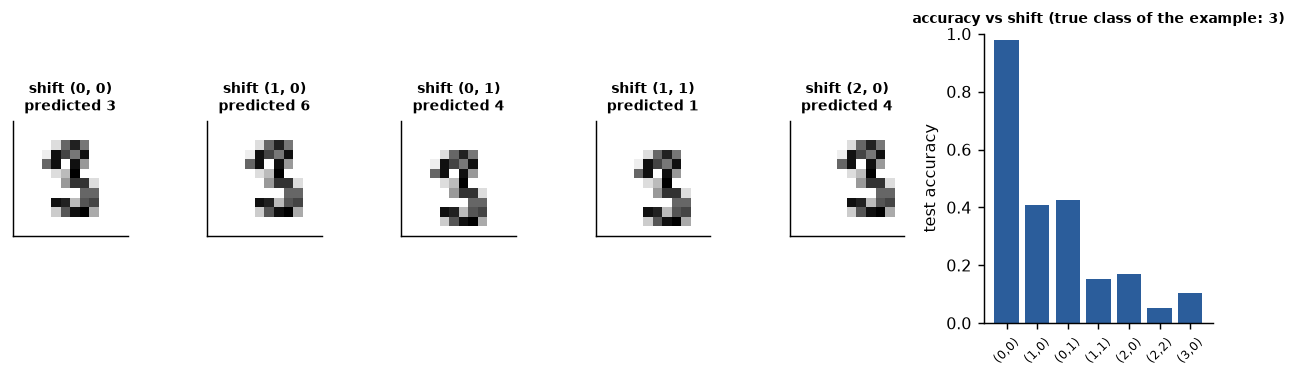

In [24]:
# Sensibilidad del perceptrón a un desplazamiento de las imágenes de prueba (dígitos rellenados hasta 12 x 12).
def shift_all(I, dx, dy):
    '''Shift every image of the stack I by (dx, dy) pixels, filling with zeros.'''
    return np.array([ndimage.shift(im, (dy, dx), order=0, cval=0.0) for im in I])
flat = lambda I: I.reshape(len(I), -1)
I_pad = np.pad(I_dig, ((0, 0), (2, 2), (2, 2)))                                 # 1797 x 12 x 12
Itr, Ite, ytr, yte = train_test_split(I_pad, y_dig, test_size=0.3, random_state=0, stratify=y_dig)
raw_mlp = mlp((128,), max_iter=300).fit(flat(Itr), ytr)
shifts = [(0, 0), (1, 0), (0, 1), (1, 1), (2, 0), (2, 2), (3, 0)]
acc_raw = [raw_mlp.score(flat(shift_all(Ite, dx, dy)), yte) for dx, dy in shifts]
print("test accuracy of the perceptron when the test digits are shifted by (dx, dy) pixels:")
print("   ".join(f"{s}: {a:.3f}" for s, a in zip(shifts, acc_raw)))

k = int(np.where((raw_mlp.predict(flat(Ite)) == yte) & (yte == 3))[0][0])         # un '3' de prueba clasificado correctamente sin desplazamiento
fig, axes = plt.subplots(1, 6, figsize=(9.5, 3.0), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1, 2.0]})
for ax, (dx, dy) in zip(axes[:5], shifts[:5]):
    ax.imshow(shift_all(Ite[k:k + 1], dx, dy)[0], cmap="gray_r"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"shift ({dx}, {dy})\npredicted {raw_mlp.predict(flat(shift_all(Ite[k:k + 1], dx, dy)))[0]}", fontsize=8)
axes[5].bar([f"({dx},{dy})" for dx, dy in shifts], acc_raw, color="#2b5d9b"); axes[5].set_ylim(0, 1); axes[5].set_ylabel("test accuracy")
axes[5].set_title(f"accuracy vs shift (true class of the example: {yte[k]})", fontsize=8); axes[5].tick_params(axis="x", labelsize=6.5, rotation=45)
fig.tight_layout()

<p class="caption"><b>Figura 14.</b> Izquierda: un dígito reservado desplazado hasta en dos píxeles, con la predicción del perceptrón bajo cada uno. Derecha: exactitud de prueba en función del desplazamiento. La exactitud sin desplazamiento es de alrededor de 0.98; un desplazamiento de <em>un píxel</em> —un doceavo de la imagen— la reduce a menos de la mitad, y dos píxeles la dejan cerca del azar. Nada de los dígitos cambió; solo cambió su posición. Una radiografía nunca se posiciona con precisión de un píxel, y una lesión puede aparecer en cualquier lugar del campo de visión, de modo que esta fragilidad sería descalificante en la práctica. La Sección 2.3 ofrece un remedio, el aumento de datos con copias desplazadas; la Sección 6.4 mide hasta dónde llega y presenta el segundo remedio, que es arquitectónico.</p>

### 6.2 La convolución, a mano

Una **convolución** desliza una pequeña matriz de pesos —el **kernel** o **filtro**, típicamente de 3 × 3— sobre la imagen y, en cada posición, entrega la suma de los productos de los elementos del kernel por los píxeles que quedan bajo ellos:

<div class="eq">$$(\mathbf{I} \star \mathbf{K})_{r,c} = \sum_{u=0}^{k-1} \sum_{v=0}^{k-1} K_{u,v}\, I_{r+u,\, c+v}$$
<span class="where">La salida es un <strong>mapa de características</strong> (feature map): grande donde la imagen se parece localmente al kernel. En el borde de la imagen, los vecinos faltantes se rellenan con ceros (zero padding) o, como en la Sección 6.3, reflejando la imagen. En sentido estricto, esta operación es una <em>correlación cruzada</em>; una convolución matemática invierte primero el kernel. Las bibliotecas de aprendizaje profundo calculan la correlación cruzada y la llaman convolución, y como los kernels se aprenden, la distinción es irrelevante. Sin relleno, un kernel de $k \times k$ sobre una imagen de $H \times W$ da un mapa de $(H - k + 1) \times (W - k + 1)$ ("valid"); rellenar la imagen con $\lfloor k/2 \rfloor$ ceros por cada lado conserva el tamaño ("same").</span></div>

Los mismos nueve pesos se aplican en todas las posiciones: el kernel es una *única* plantilla compartida en toda la imagen, a diferencia de los 64 pesos independientes por unidad del perceptrón. Ese compartir pesos es lo que da a la operación su **equivariancia a la traslación** —si se desplaza la imagen, el mapa de características se desplaza con ella y, por lo demás, no cambia—, y el paso de pooling que sigue convierte la equivariancia en invariancia (local). Toma una imagen de 4 × 4 con un borde vertical en su mitad superior y el kernel de bordes verticales $\mathbf{K}$:

$$\mathbf{I} = \begin{pmatrix} 1 & 1 & 5 & 5 \\ 1 & 1 & 5 & 5 \\ 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 \end{pmatrix}, \qquad \mathbf{K} = \begin{pmatrix} -1 & 0 & 1 \\ -1 & 0 & 1 \\ -1 & 0 & 1 \end{pmatrix}$$

La salida "valid" es de 2 × 2. En la posición (0, 0) la ventana es el bloque de 3 × 3 superior izquierdo; cada una de sus filas aporta $-1 \cdot (\text{left}) + 0 + 1 \cdot (\text{right})$: las filas 1 y 2 dan $-1 + 5 = 4$ cada una, la fila 3 da $-1 + 1 = 0$, total $8$. En (0, 1) la ventana se mueve una columna a la derecha: las filas 1 y 2 dan $-1 + 5 = 4$, la fila 3 da $0$, total $8$. En (1, 0) la ventana cubre las filas 2–4: la fila 2 da $4$, las filas 3 y 4 dan $0$, total $4$; en (1, 1), igualmente, $4$. Así,

$$\mathbf{I} \star \mathbf{K} = \begin{pmatrix} 8 & 8 \\ 4 & 4 \end{pmatrix}.$$

El mapa es grande donde está el borde (arriba) y menor donde la ventana lo cubre solo en parte. Con el kernel transpuesto $\mathbf{K}^\top$ (un detector de bordes horizontales: $-1$ en la fila superior, $+1$ en la inferior), la posición (0, 0) da $-(1 + 1 + 5) + (1 + 1 + 1) = -4$ y la posición (0, 1) da $-(1 + 5 + 5) + 3 = -8$; la segunda fila los repite: $\begin{pmatrix} -4 & -8 \\ -4 & -8 \end{pmatrix}$, negativos porque la imagen es brillante *por encima* del borde horizontal y el kernel espera brillo por debajo. Una **ReLU** aplicada a los mapas lleva a cero las respuestas negativas, de modo que esta imagen excita el mapa de bordes verticales y no el horizontal; un **max-pooling de 2 × 2** del mapa vertical devuelve entonces el número 8, su máximo: la afirmación "hay un borde vertical en algún lugar de esta imagen", sin importar dónde. La celda confirma los números.

In [25]:
# Confirmación de la convolución, la ReLU y el max-pooling desarrollados a mano.
I_h = np.array([[1, 1, 5, 5], [1, 1, 5, 5], [1, 1, 1, 1], [1, 1, 1, 1]], float)
K_v = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], float)
def conv2d(I, K):
    '''Valid cross-correlation written out as the double sum of the formula (no library call).'''
    k = K.shape[0]; H, W = I.shape
    return np.array([[(K * I[r:r + k, c:c + k]).sum() for c in range(W - k + 1)] for r in range(H - k + 1)])
def maxpool(M, s=2):
    return M.reshape(M.shape[0] // s, s, M.shape[1] // s, s).max(axis=(1, 3))
mv, mh = conv2d(I_h, K_v), conv2d(I_h, K_v.T)
print("vertical-edge map:\n", mv, "\nhorizontal-edge map:\n", mh)
print("agrees with scipy.signal.correlate2d:", np.allclose(mv, signal.correlate2d(I_h, K_v, mode="valid")))
print("after ReLU and 2 x 2 max-pooling -> vertical:", maxpool(np.maximum(mv, 0)).ravel(), " horizontal:", maxpool(np.maximum(mh, 0)).ravel())

vertical-edge map:
 [[8. 8.]
 [4. 4.]] 
horizontal-edge map:
 [[-4. -8.]
 [-4. -8.]]
agrees with scipy.signal.correlate2d: True
after ReLU and 2 x 2 max-pooling -> vertical: [8.]  horizontal: [0.]


El código reproduce el resultado a mano —$\begin{pmatrix} 8 & 8 \\ 4 & 4 \end{pmatrix}$ para el kernel vertical, $\begin{pmatrix} -4 & -8 \\ -4 & -8 \end{pmatrix}$ para el horizontal— y <code>scipy.signal.correlate2d</code> coincide con la doble suma explícita. Tras la ReLU y el pooling, la imagen queda resumida en dos números, 8 y 0: "un borde vertical, ningún borde horizontal".

### 6.3 Mapas de características y pooling en imágenes reales

La celda aplica un pequeño **banco de filtros fijos** —detectores de bordes de Sobel vertical y horizontal, un laplaciano (responde a puntos y líneas finas), un desenfoque gaussiano y un detector de "manchas" (blobs) por diferencia de gaussianas ajustado al tamaño de los nódulos simulados— a un dígito y a un parche con nódulo, con relleno "same", y muestra los mapas antes y después de un max-pooling de 4 × 4.

map sizes: digit 12 x 12 -> (3, 3) | patch 32 x 32 -> (8, 8)


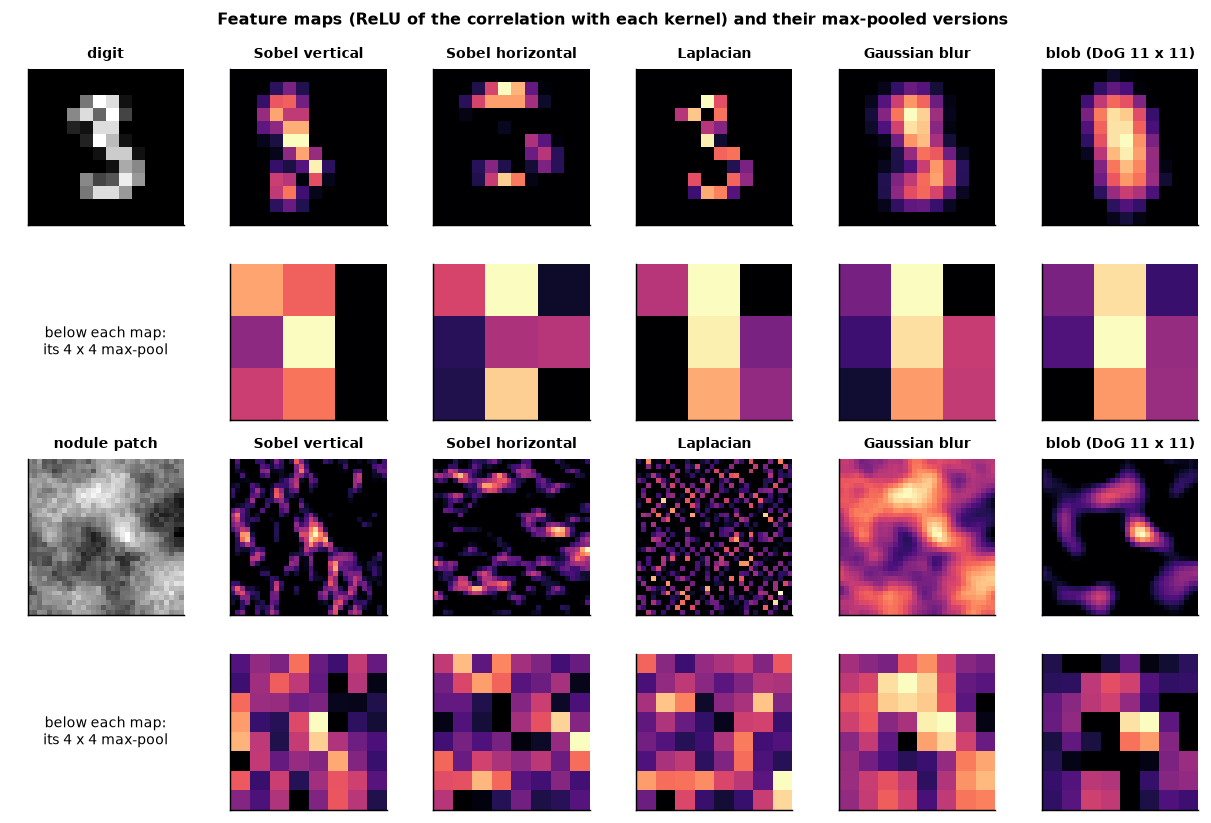

In [26]:
# Un banco de filtros fijos, sus mapas de características en un dígito y en un parche con nódulo, y los mapas tras el pooling.
def gauss2d(sigma, size):
    r = np.arange(size) - size // 2; g = np.exp(-(r[:, None] ** 2 + r[None, :] ** 2) / (2 * sigma ** 2)); return g / g.sum()
FILTERS = {"Sobel vertical": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float), "Sobel horizontal": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], float),
           "Laplacian": np.array([[0, -1, 0], [-1, 4, -1], [0, -1, 0]], float), "Gaussian blur": gauss2d(1.0, 3),
           "blob (DoG 11 x 11)": gauss2d(2.5, 11) - gauss2d(5.0, 11)}
def feature_maps(img, bank):
    '''ReLU of the "same"-padded cross-correlation with every kernel of the bank.'''
    return [np.maximum(signal.correlate2d(img, K, mode="same", boundary="symm"), 0) for K in bank]
examples = [("digit", I_pad[y_dig == 3][0]), ("nodule patch", nod_X[nod_y == 1][0])]
fig, axes = plt.subplots(4, 6, figsize=(9.5, 6.4))
for r2, (name, im) in enumerate(examples):
    maps = feature_maps(im, FILTERS.values()); pool = 4
    axes[2 * r2, 0].imshow(im); axes[2 * r2, 0].set_title(name, fontsize=8); axes[2 * r2 + 1, 0].axis("off")
    axes[2 * r2 + 1, 0].text(0.5, 0.5, f"below each map:\nits {pool} x {pool} max-pool", ha="center", va="center", fontsize=7.5, transform=axes[2 * r2 + 1, 0].transAxes)
    for c, (fname, M) in enumerate(zip(FILTERS, maps), start=1):
        axes[2 * r2, c].imshow(M, cmap="magma"); axes[2 * r2, c].set_title(fname, fontsize=7.5)
        axes[2 * r2 + 1, c].imshow(maxpool(M, pool), cmap="magma")
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Feature maps (ReLU of the correlation with each kernel) and their max-pooled versions", fontsize=9, fontweight="bold"); fig.tight_layout()
print("map sizes: digit 12 x 12 ->", maxpool(feature_maps(examples[0][1], FILTERS.values())[0], 4).shape, "| patch 32 x 32 ->", maxpool(feature_maps(examples[1][1], FILTERS.values())[0], 4).shape)

<p class="caption"><b>Figura 15.</b> Filas 1 y 3: un dígito y un parche con nódulo, con los cinco mapas de características producidos por el banco de filtros fijos; filas 2 y 4: los mismos mapas tras un max-pooling de 4 × 4. Los mapas de Sobel se iluminan sobre los trazos del dígito según su orientación; el laplaciano responde a estructuras finas y al ruido; el mapa de desenfoque es una copia suavizada; el detector de manchas responde de forma intensa y selectiva al nódulo y débilmente a la textura de fondo: es una plantilla de "un objeto brillante y redondo de aproximadamente este tamaño" aplicada en cada posición. El pooling descarta la posición exacta dentro de cada bloque de 4 × 4, pero conserva la información de que la característica estaba presente: un nódulo desplazado en uno o dos píxeles cae en la misma celda agrupada. Apilar varias veces convolución, no linealidad y pooling, con kernels <em>aprendidos</em> por retropropagación en lugar de fijos, es la red neuronal convolucional de LeCun y colaboradores,<sup class="c"><a href="#r14">[14]</a></sup> y la que ganó ImageNet en 2012.<sup class="c"><a href="#r16">[16]</a></sup></p>

### 6.4 Una etapa convolucional inicial mínima, y el regreso de la robustez ante desplazamientos

La celda ensambla las piezas en una **red convolucional de filtros fijos**: el banco de filtros, una ReLU, max-pooling de 4 × 4, el máximo y la media globales de cada mapa, y un perceptrón de scikit-learn sobre el vector resultante. Nada en la etapa inicial se aprende —los filtros son los diseñados a mano más arriba—, de modo que esta no es una red convolucional en sentido pleno; es una demostración de que la *estructura* de la convolución y el pooling, y no solo el aprendizaje de los filtros, es lo que proporciona robustez. El experimento repite la prueba de desplazamiento de la Sección 6.1 para cuatro sistemas: el perceptrón con píxeles crudos; el perceptrón con píxeles crudos entrenado con aumento por desplazamiento (cuatro copias desplazadas en un píxel de cada imagen de entrenamiento, Sección 2.3); la etapa convolucional inicial; y la etapa inicial con aumento de datos.

In [27]:
# Robustez ante desplazamientos de cuatro sistemas: MLP crudo, MLP crudo + aumento, etapa conv inicial, etapa conv inicial + aumento.
def conv_features(I, bank, pool=4):
    '''Fixed-filter convolutional front end: ReLU maps -> pool x pool max-pooling -> flatten, plus global max and mean per map.'''
    out = []
    for im in I:
        maps = feature_maps(im, bank)
        out.append(np.concatenate([maxpool(M, pool).ravel() for M in maps] + [np.array([M.max(), M.mean()]) for M in maps]))
    return np.array(out)
bank_d = list(FILTERS.values())[:4]                                               # dígitos: no se necesita el detector de manchas
Itr_aug = np.concatenate([Itr] + [shift_all(Itr, dx, dy) for dx, dy in [(1, 0), (-1, 0), (0, 1), (0, -1)]]); ytr_aug = np.tile(ytr, 5)
systems = {"raw pixels":                     (flat, Itr, ytr),
           "raw pixels + shift augmentation": (flat, Itr_aug, ytr_aug),
           "conv front end":                  (lambda I: conv_features(I, bank_d), Itr, ytr),
           "conv front end + augmentation":   (lambda I: conv_features(I, bank_d), Itr_aug, ytr_aug)}
table = {}
for name, (fn, Xtrain, ytrain) in systems.items():
    m = mlp((128,), max_iter=300).fit(fn(Xtrain), ytrain)
    table[name] = {f"shift {s}": round(m.score(fn(shift_all(Ite, *s)), yte), 3) for s in shifts}
print("features per image: raw", flat(Itr[:1]).shape[1], "| conv front end", conv_features(Itr[:1], bank_d).shape[1])
pd.DataFrame(table).T

features per image: raw 144 | conv front end 44


,"shift (0, 0)","shift (1, 0)","shift (0, 1)","shift (1, 1)","shift (2, 0)","shift (2, 2)","shift (3, 0)"
raw pixels,0.978,0.409,0.426,0.154,0.170,0.054,0.106
raw pixels + shift augmentation,0.993,0.980,0.987,0.581,0.391,0.044,0.152
conv front end,0.974,0.526,0.852,0.480,0.291,0.181,0.115
conv front end + augmentation,0.963,0.952,0.952,0.844,0.746,0.341,0.319


Lee la tabla fila por fila. El **perceptrón con píxeles crudos** colapsa con un píxel. El **aumento de datos** repara exactamente los desplazamientos que se le mostraron —un píxel en cada dirección— y cae a alrededor de 0.4 con un desplazamiento de dos píxeles y al nivel del azar con uno diagonal: la red memorizó cuatro posiciones adicionales; no aprendió que la posición es irrelevante. La **etapa convolucional inicial** sola, con filtros fijos y una única etapa de pooling, es solo parcialmente robusta: el pooling de 4 × 4 tolera un desplazamiento solo mientras la característica permanezca en el mismo bloque. La **combinación** es, por lejos, la más robusta con dos y tres píxeles: la representación agrupada hace que un dígito desplazado se *vea parecido* para la red, de modo que la invariancia aprendida a partir de ejemplos de un píxel se extrapola a desplazamientos que nunca vio. Esa extrapolación es justamente lo que se llama un **sesgo inductivo**: un supuesto incorporado en la arquitectura que permite al modelo generalizar más allá de los casos de la muestra, y es la razón por la que las redes convolucionales aprendieron a partir de miles de radiografías lo que los perceptrones no podían aprender a partir de millones de píxeles.

<div class="box key"><h4>De esta etapa inicial al aprendizaje profundo, y al aprendizaje por transferencia</h4><p>Una red convolucional real difiere de la celda anterior en tres aspectos. Sus filtros se <em>aprenden</em> por retropropagación junto con el clasificador, de modo que el detector de manchas que ajustamos a mano se descubre a partir de los datos, y también detectores que a nadie se le ocurrió diseñar. Apila varios bloques de convolución–ReLU–pooling, de modo que las capas posteriores combinan bordes en partes y partes en objetos. Y se entrena con muchas más imágenes de las que tiene un hospital; por eso el <strong>aprendizaje por transferencia</strong> (transfer learning) es la receta estándar en imágenes médicas: a una red preentrenada con los 1.2 millones de imágenes naturales de ImageNet<sup class="c"><a href="#r16">[16]</a></sup> se le reemplaza la última capa y se la ajusta finamente (fine-tuning) con unos pocos miles de imágenes médicas. Shin y colaboradores mostraron que los filtros aprendidos con fotografías se transfieren de manera útil a la CT, porque los bordes, las manchas y las texturas son universales;<sup class="c"><a href="#r17">[17]</a></sup> todos los artículos fundamentales de la Sección 8 lo usaron. Este notebook no ejecuta una red profunda, porque el curso no usa ningún framework de aprendizaje profundo; MedMNIST<sup class="c"><a href="#r8">[8]</a></sup> con PyTorch o Keras es el lugar para hacerlo después.</p></div>

### 6.5 La misma lección con los parches simulados

Los parches permiten un experimento complementario que los dígitos no permiten: la **posición de la lesión** es un parámetro del generador. La celda genera tres conjuntos de datos de nódulos de 600 parches en los que el centro de la lesión se desplaza aleatoriamente hasta 2, 6 y 12 píxeles alrededor del centro del parche de 32 × 32, y evalúa con validación cruzada el mismo perceptrón con tres representaciones: los píxeles crudos, las 14 características diseñadas a mano de la Sección 3 y la etapa convolucional inicial con el detector de manchas.

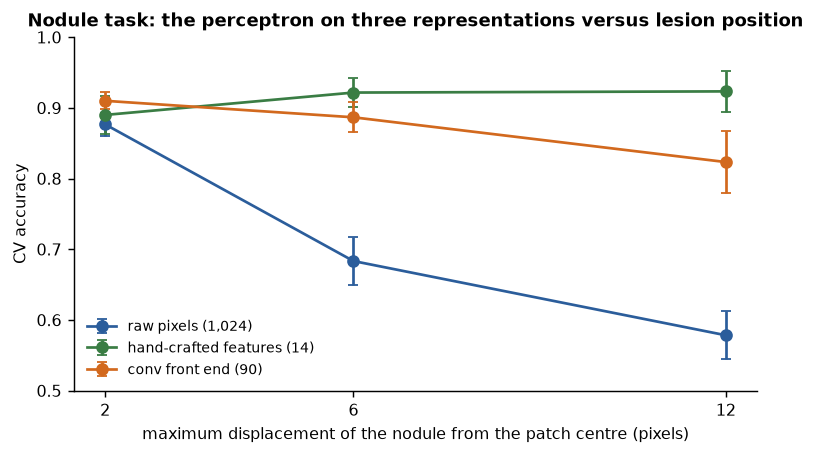

,jitter 2 px,jitter 6 px,jitter 12 px
"raw pixels (1,024)",0.877 ± 0.016,0.683 ± 0.034,0.578 ± 0.034
hand-crafted features (14),0.890 ± 0.027,0.922 ± 0.020,0.923 ± 0.029
conv front end (90),0.910 ± 0.012,0.887 ± 0.021,0.823 ± 0.043


In [28]:
# Exactitud frente al desplazamiento aleatorio de la posición de la lesión para tres representaciones (mismo perceptrón, 5 pliegues estratificados).
bank_p = list(FILTERS.values())                                                   # parches: los cinco filtros, incluido el detector de manchas
jitters, reps = [2, 6, 12], {}
for j in jitters:
    Xj, yj = make_patches(600, "nodule", jitter=j, rng=np.random.default_rng(20 + j))
    Fj = np.array([extract_features(im) for im in Xj]); Cj = conv_features(Xj, bank_p, pool=8)
    for rep, Xin in [("raw pixels (1,024)", flat(Xj)), ("hand-crafted features (14)", Fj), (f"conv front end ({Cj.shape[1]})", Cj)]:
        reps.setdefault(rep, []).append(cv_summary(MLPClassifier((64,), alpha=1.0, max_iter=300, random_state=0), Xin, yj))
fig, ax = plt.subplots(figsize=(6, 3.6))
for (rep, vals), col in zip(reps.items(), ("#2b5d9b", "#3a7d44", "#d2691e")):
    ax.errorbar(jitters, [v[0] for v in vals], yerr=[v[1] for v in vals], fmt="o-", color=col, capsize=3, label=rep)
ax.set_xlabel("maximum displacement of the nodule from the patch centre (pixels)"); ax.set_ylabel("CV accuracy"); ax.set_ylim(0.5, 1.0)
ax.set_xticks(jitters); ax.legend(frameon=False, fontsize=8); ax.set_title("Nodule task: the perceptron on three representations versus lesion position")
fig.tight_layout()
pd.DataFrame({rep: [f"{m:.3f} ± {s:.3f}" for m, s in vals] for rep, vals in reps.items()}, index=[f"jitter {j} px" for j in jitters]).T

<p class="caption"><b>Figura 16.</b> Exactitud de validación cruzada del mismo perceptrón de 64 unidades con tres representaciones de los parches con nódulos, a medida que se permite que la lesión se aleje más del centro. Con píxeles crudos, la red se degrada desde cerca de 0.9 hasta menos de 0.6 cuando el nódulo puede estar en cualquier lugar: tiene que aprender una plantilla distinta para cada posición, y seiscientas imágenes no bastan. Las características diseñadas a mano son invariantes por construcción —el área, el contraste y la textura no dependen de dónde esté la mancha— y su curva es plana dentro de sus barras de error. La etapa convolucional inicial es la mejor representación cuando la lesión está casi centrada y queda entre las otras dos con desplazamientos grandes: su detector de manchas se aplica en todas partes y su pooling descarta la posición dentro de bloques de 8 × 8, de modo que se degrada de forma gradual; una red con filtros aprendidos y más etapas de pooling sería aún más plana. La figura resume todo el argumento de la sección en una sola imagen: con pocos datos, la invariancia debe venir de algún lugar distinto de los datos, ya sea de características diseñadas o de la arquitectura.</p>

<div class="exercise"><h4>Ejercicio 4</h4><p>Reemplaza <code>pool=8</code> por <code>pool=32</code> en la celda del desplazamiento aleatorio, de modo que cada mapa se reduzca a un único máximo y una única media globales (10 características en total). La representación es ahora completamente invariante a la traslación; ¿sigue siendo discriminativa? Luego pasa el conjunto de microcalcificaciones (<code>mc_X, mc_y</code>) por las mismas tres representaciones. ¿Qué filtro del banco transporta la señal para esa tarea, y por qué fallan en ella las características de primer orden?</p></div>

## 7. Qué puede salir mal en la clasificación de imágenes médicas

### 7.1 Aprendizaje por atajos: la red aprende el hospital

La Unidad 1 simuló un identificador de equipo que predecía la etiqueta en el hospital de entrenamiento y no en otros lugares. Con imágenes, el factor de confusión no necesita ser una columna aparte: puede estar *en los píxeles*. Zech y colaboradores entrenaron una red convolucional para detectar neumonía en radiografías reunidas de varios hospitales y encontraron que identificaba el hospital de origen a partir de la imagen con una exactitud casi perfecta —a partir de marcadores de lateralidad, texto incrustado, el campo de visión— y usaba la prevalencia de neumonía del hospital como predictor, de modo que su rendimiento externo quedaba muy por debajo de su validación cruzada interna.<sup class="c"><a href="#r18">[18]</a></sup> Geirhos y colaboradores llamaron a este fenómeno **aprendizaje por atajos** (shortcut learning): el modelo encuentra la regularidad más fácil que predice la etiqueta en la distribución de entrenamiento, sea o no la buscada.<sup class="c"><a href="#r19">[19]</a></sup> DeGrave y colaboradores mostraron que los detectores de COVID-19 en radiografías de 2020 —con positivos de un conjunto de fuentes y negativos de otro— se apoyaban en marcadores, bordes de la imagen y la posición de los hombros en lugar de en los pulmones.<sup class="c"><a href="#r20">[20]</a></sup> La celda reproduce el mecanismo con el hospital A, cuyos parches positivos llevan un marcador en la esquina el 90 % de las veces, y evalúa el perceptrón con parches nuevos del mismo hospital y de un hospital B sin marcadores.

In [29]:
# Aprendizaje por atajos en imágenes: un marcador en la esquina que acompaña a los casos positivos solo en el hospital de entrenamiento.
rngA = np.random.default_rng(10)
XA, yA = make_patches(1000, "nodule", hospital="A", marker_rate=0.9, rng=rngA)         # hospital de entrenamiento (marcador en el 90 % de los positivos)
XA2, yA2 = make_patches(400, "nodule", hospital="A", marker_rate=0.9, rng=rngA)        # casos nuevos, mismo hospital
XB, yB = make_patches(400, "nodule", hospital="B", rng=np.random.default_rng(11))      # otro hospital: sin marcadores
XH, yH = make_patches(1000, "nodule", hospital="B", rng=np.random.default_rng(12))     # un conjunto de entrenamiento sin marcadores, para comparar
pix_mlp = lambda: make_pipeline(StandardScaler(), MLPClassifier((64,), alpha=1.0, max_iter=300, random_state=0))
shortcut_model, honest_model = pix_mlp().fit(flat(XA), yA), pix_mlp().fit(flat(XH), yH)
res = pd.DataFrame({
    "training accuracy":               [shortcut_model.score(flat(XA), yA), honest_model.score(flat(XH), yH)],
    "new cases, same hospital":        [shortcut_model.score(flat(XA2), yA2), honest_model.score(flat(XA2), yA2)],
    "new cases, hospital B (no marker)": [shortcut_model.score(flat(XB), yB), honest_model.score(flat(XB), yB)],
}, index=["trained at hospital A (marker)", "trained without markers"]).round(3)
print("fraction of hospital-A positives that carry the marker:", round(float((XA[yA == 1][:, 1:4, 26:31] > 0.9).all(axis=(1, 2)).mean()), 2))
res

fraction of hospital-A positives that carry the marker: 0.89


,training accuracy,"new cases, same hospital","new cases, hospital B (no marker)"
trained at hospital A (marker),1.0,0.962,0.732
trained without markers,1.0,0.875,0.882


El modelo entrenado en el hospital A se ve excelente en casa —su exactitud con casos nuevos del mismo hospital está muy por encima de la del modelo sin marcadores, porque el marcador es una pista mucho más fácil que un nódulo tenue— y pierde más de veinte puntos en el hospital B, donde debe apoyarse en lo que sea que haya aprendido sobre los nódulos, que es menos de lo que aprendió el modelo sin marcadores. Como en la Unidad 1, ningún número interno advirtió de la falla: la exactitud de entrenamiento y la exactitud en el mismo hospital eran ambas altas. La causa puede hacerse visible, y ese es el tema de la sección siguiente.

### 7.2 ¿Dónde está mirando la red? Sensibilidad a la oclusión

Un **mapa de saliencia** muestra qué partes de una imagen impulsan una predicción. El más simple, introducido por Zeiler y Fergus, es la **sensibilidad a la oclusión**: cubre un pequeño cuadrado de la imagen con un valor neutro, registra cuánto baja la probabilidad predicha de la clase, mueve el cuadrado y repite; el mapa de caídas muestra dónde está la evidencia.<sup class="c"><a href="#r21">[21]</a></sup> No requiere más que la capacidad de llamar a <code>predict_proba</code>, por lo que funciona tanto para un perceptrón como para una red profunda. Aquí la caída se mide en log-odds (logaritmo de la razón de probabilidades), $\log[p/(1-p)]$, en lugar de en probabilidad, porque un modelo confiado entrega $p \approx 1$ para muchos parches, y una caída de 0.999 a 0.99 —un cambio de diez veces en las odds— sería invisible en la escala de probabilidad. La celda la calcula para los dos modelos de la Sección 7.1 en tres parches positivos del hospital A que llevan el marcador.

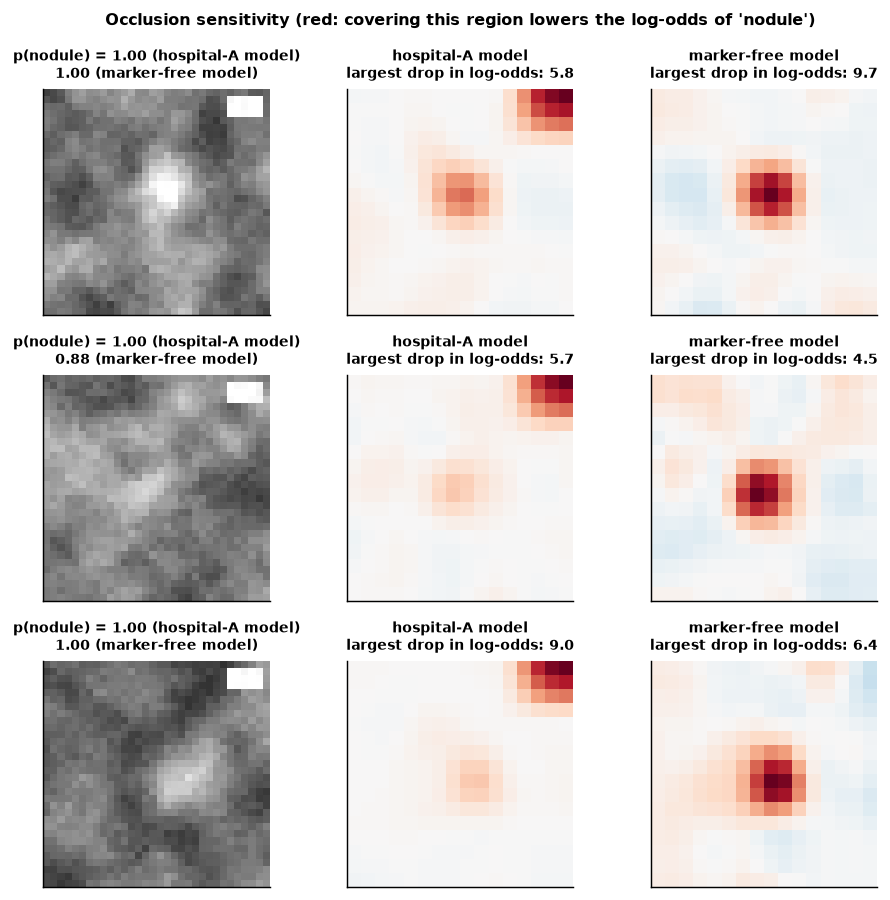

In [30]:
# Mapas de sensibilidad a la oclusión: caída de p(nodule) cuando un cuadrado de 6 x 6 se reemplaza por la media del parche.
def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
def occlusion_map(model, img, size=6, step=2):
    '''Average drop in the log-odds of "nodule" when a size x size square around each pixel is replaced by the patch mean.'''
    base = model.predict_proba(img.reshape(1, -1))[0, 1]
    H, N = np.zeros(img.shape), np.zeros(img.shape)
    for r in range(0, img.shape[0] - size + 1, step):
        for c in range(0, img.shape[1] - size + 1, step):
            oc = img.copy(); oc[r:r + size, c:c + size] = img.mean()
            H[r:r + size, c:c + size] += logit(base) - logit(model.predict_proba(oc.reshape(1, -1))[0, 1]); N[r:r + size, c:c + size] += 1
    return H / np.maximum(N, 1), base
idx = np.where((yA2 == 1) & (XA2[:, 2, 28] > 0.9))[0][:3]                         # parches positivos que llevan el marcador
fig, axes = plt.subplots(3, 3, figsize=(7.2, 7))
for row, i in enumerate(idx):
    Hs, ps = occlusion_map(shortcut_model, XA2[i]); Hh, ph = occlusion_map(honest_model, XA2[i])
    axes[row, 0].imshow(XA2[i], vmin=0, vmax=1); axes[row, 0].set_title(f"p(nodule) = {ps:.2f} (hospital-A model)\n{ph:.2f} (marker-free model)", fontsize=8)
    for ax, Hm, t in [(axes[row, 1], Hs, "hospital-A model"), (axes[row, 2], Hh, "marker-free model")]:
        v = np.abs(Hm).max() + 1e-9; ax.imshow(Hm, cmap="RdBu_r", vmin=-v, vmax=v); ax.set_title(f"{t}\nlargest drop in log-odds: {Hm.max():.1f}", fontsize=8)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Occlusion sensitivity (red: covering this region lowers the log-odds of 'nodule')", fontsize=9, fontweight="bold"); fig.tight_layout()

<p class="caption"><b>Figura 17.</b> Tres parches positivos del hospital A (izquierda) y los mapas de sensibilidad a la oclusión de los dos modelos. Para el modelo entrenado en el hospital A (centro), la evidencia es el marcador de la esquina: cubrirlo hace colapsar la probabilidad, y cubrir el nódulo cambia poco. Para el modelo sin marcadores (derecha), la evidencia es el propio nódulo. Cuando un parche lleva un nódulo intenso <em>y</em> el marcador, el modelo del hospital A también muestra cierta sensibilidad al nódulo, porque aprendió ambas pistas; el marcador sigue siendo la dominante. Los mapas son gruesos —el oclusor es de 6 × 6 píxeles y se mueve en pasos de 2—, pero habrían revelado el atajo antes del despliegue, que es como se descubrieron los marcadores y bordes de los detectores de COVID-19.<sup class="c"><a href="#r20">[20]</a></sup> Los mapas de saliencia tienen sus propios límites: muestran <em>dónde</em> miró el modelo, no <em>por qué</em>, pueden ser ruidosos, y un mapa que resalta la lesión no demuestra que el modelo la haya comprendido. Usados como herramienta de depuración, como aquí, son indispensables.</p>

<div class="box warn"><h4>El atajo no tiene por qué ser un marcador</h4><p>Cualquier variable que se correlacione con la etiqueta en la muestra de entrenamiento y sea visible en los píxeles puede ser un atajo: el modelo del equipo (a través de la textura del ruido), el servicio clínico (las radiografías portátiles se toman a pacientes más graves), la presencia de un drenaje torácico en imágenes de neumotórax —un caso documentado por Oakden-Rayner y colaboradores, cuya red detectaba el tratamiento en lugar de la condición<sup class="c"><a href="#r22">[22]</a></sup>— o la regla colocada junto a las lesiones de las que los dermatólogos ya sospechan. La defensa es la que dio la Unidad 1: evaluar con datos de otro centro, estratificar la evaluación según cada variable que pudiera ser un atajo, y mirar los mapas de saliencia de los errores <em>y</em> de los aciertos con alta confianza.</p></div>

### 7.3 Desbalance de clases, prevalencia y ruido en las etiquetas

Dos propiedades de los conjuntos de datos de imágenes reales que las simulaciones balanceadas ocultan merecen un experimento cada una. **Desbalance de clases**: en el tamizaje, los positivos son raros, y un clasificador entrenado con un 95 % de negativos aprende que "negativo" es una buena respuesta; su exactitud es alta y su sensibilidad es baja. El perceptrón de scikit-learn no tiene la opción <code>class_weight</code>, por lo que los remedios son remuestrear los pliegues de entrenamiento o —lo más simple y a menudo lo mejor— conservar el modelo y **mover el umbral**, como hizo la Sección 4.5. **Ruido en las etiquetas**: las etiquetas de los grandes conjuntos de datos de radiografías se extrajeron de los informes mediante minería de texto y son erróneas en una fracción conocida de los casos;<sup class="c"><a href="#r3">[3]</a></sup> la revisión de Frénay y Verleysen examina lo que el ruido les hace a los clasificadores.<sup class="c"><a href="#r23">[23]</a></sup> Ocurren dos cosas: el modelo aprende peor y —de forma más insidiosa— la exactitud *medida* en un conjunto de prueba con etiquetas ruidosas queda acotada por debajo de la exactitud real, de modo que un modelo perfecto parece imperfecto y un modelo que ha aprendido el ruido parece mejor de lo que es.

In [31]:
# Desbalance de clases (5 % de positivos): la exactitud halaga, la sensibilidad revela; mover el umbral la restituye.
Xneg, _ = make_patches(950, "nodule", positive=False, rng=np.random.default_rng(30))
Xpos, _ = make_patches(50, "nodule", positive=True, rng=np.random.default_rng(31))
X_imb = np.array([extract_features(im) for im in np.concatenate([Xneg, Xpos])]); y_imb = np.r_[np.zeros(950, int), np.ones(50, int)]
p_imb = cross_val_predict(make_pipeline(StandardScaler(), MLPClassifier((64,), alpha=1.0, max_iter=300, random_state=0)),
                          X_imb, y_imb, cv=cv5, method="predict_proba")[:, 1]
def metrics(pred, y):
    return {"accuracy": (pred == y).mean(), "sensitivity": pred[y == 1].mean(), "specificity": 1 - pred[y == 0].mean(), "positives called": int(pred.sum())}
fpr_i, tpr_i, thr_i = roc_curve(y_imb, p_imb)
t90 = thr_i[np.argmax(tpr_i >= 0.90)]                                            # umbral más bajo que alcanza un 90 % de sensibilidad
rows = {"always 'negative'": metrics(np.zeros_like(y_imb), y_imb), "MLP, threshold 0.5": metrics((p_imb >= 0.5).astype(int), y_imb),
        f"MLP, threshold {t90:.2f} (for 90 % sensitivity)": metrics((p_imb >= t90).astype(int), y_imb)}
print(f"prevalence in this set: {y_imb.mean():.1%} | ROC-AUC: {roc_auc_score(y_imb, p_imb):.3f}")
pd.DataFrame(rows).T.round(3)

prevalence in this set: 5.0% | ROC-AUC: 0.944


,accuracy,sensitivity,specificity,positives called
always 'negative',0.950,0.00,1.000,0.0
"MLP, threshold 0.5",0.989,0.78,1.000,39.0
"MLP, threshold 0.05 (for 90 % sensitivity)",0.960,0.90,0.963,80.0


La regla trivial que declara todo negativo tiene una exactitud de 0.95 —la prevalencia de negativos— y una sensibilidad de cero. El perceptrón con las características diseñadas a mano lo hace mejor que eso con el umbral por defecto —su exactitud es cercana a 0.99— y aun así no detecta alrededor de una quinta parte de los nódulos, porque con 50 positivos entre 1,000 la forma más barata de reducir la pérdida de entrenamiento es ser conservador; el ROC-AUC muestra que sus probabilidades ordenan bien los casos. Bajar el umbral hasta el valor que alcanza un 90 % de sensibilidad recupera la mayoría de los casos no detectados a costa del doble de positivos declarados y de una exactitud *menor*, apenas superior a la de la regla trivial. En una tarea desbalanceada, la exactitud no mide nada útil (Suplemento S1); sí lo hacen la sensibilidad, la especificidad, la curva ROC y, para el clínico, el PPV a la prevalencia del despliegue.

clean-label accuracy: [0.978 0.906 0.852 0.719 0.676] | noisy-label accuracy: [0.978 0.833 0.657 0.517 0.43 ]


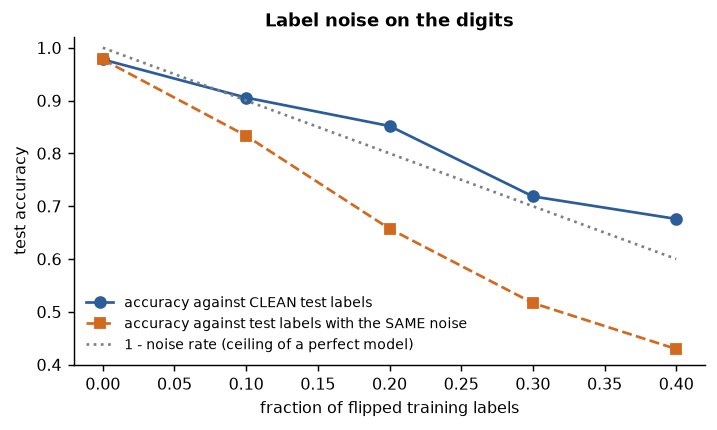

In [32]:
# Ruido en las etiquetas: se invierte una fracción de las etiquetas de ENTRENAMIENTO; la exactitud se mide con etiquetas de prueba limpias y con etiquetas igualmente ruidosas.
rng = np.random.default_rng(40)
noise_levels = [0.0, 0.1, 0.2, 0.3, 0.4]
clean_acc, noisy_acc = [], []
for q in noise_levels:
    ytr_noisy = ytr.copy(); flip = rng.random(len(ytr)) < q
    ytr_noisy[flip] = (ytr[flip] + rng.integers(1, 10, flip.sum())) % 10          # una etiqueta errónea, uniforme entre las otras nueve
    m = mlp((128,), max_iter=300).fit(flat(Itr), ytr_noisy)
    yte_noisy = yte.copy(); flip_te = rng.random(len(yte)) < q; yte_noisy[flip_te] = (yte[flip_te] + rng.integers(1, 10, flip_te.sum())) % 10
    clean_acc.append(m.score(flat(Ite), yte)); noisy_acc.append(m.score(flat(Ite), yte_noisy))
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(noise_levels, clean_acc, "o-", color="#2b5d9b", label="accuracy against CLEAN test labels")
ax.plot(noise_levels, noisy_acc, "s--", color="#d2691e", label="accuracy against test labels with the SAME noise")
ax.plot(noise_levels, 1 - np.array(noise_levels), ":", color="grey", label="1 - noise rate (ceiling of a perfect model)")
ax.set_xlabel("fraction of flipped training labels"); ax.set_ylabel("test accuracy"); ax.set_ylim(0.4, 1.02); ax.legend(frameon=False, fontsize=7.5)
ax.set_title("Label noise on the digits"); fig.tight_layout()
print("clean-label accuracy:", np.round(clean_acc, 3), "| noisy-label accuracy:", np.round(noisy_acc, 3))

<p class="caption"><b>Figura 18.</b> Exactitud de prueba del perceptrón de dígitos a medida que crece la fracción de etiquetas de entrenamiento invertidas, medida frente a etiquetas de prueba limpias (azul) y frente a etiquetas de prueba corrompidas con la misma tasa (naranja). La curva azul se degrada gradualmente —alrededor de 0.91 con 10 % de ruido y 0.85 con 20 %— porque las etiquetas erróneas, repartidas uniformemente entre nueve clases, se cancelan en parte; con más imágenes de entrenamiento la curva sería más plana. La curva naranja es la que realmente vería un investigador con etiquetas ruidosas: corre por debajo del techo gris $1 - q$ aproximadamente en el error real del modelo, de modo que un modelo que en realidad tiene una exactitud de alrededor del 85 % se <em>reporta</em> con una exactitud del 66 % con 20 % de ruido. El ruido <em>sistemático</em> —una regla de minería de informes que siempre pasa por alto un tipo de neumonía— no se promedia y es mucho más dañino; las etiquetas de incertidumbre de CheXpert<sup class="c"><a href="#r4">[4]</a></sup> y los conjuntos de prueba adjudicados por radiólogos de los artículos fundamentales existen por esta razón.</p>

### 7.4 Validación externa, estudios con lectores y la situación regulatoria de la IA en imágenes

Tres prácticas separan un modelo que funciona en un notebook de un dispositivo que funciona en un hospital. La **validación externa** evalúa el modelo congelado con datos de instituciones, equipos y períodos que no aportaron nada a su desarrollo; la lista de verificación CLAIM para la IA en imágenes médicas la convierte en un requisito de reporte, junto con la muestra, el estándar de referencia, el preprocesamiento, el procedimiento de selección del modelo y métricas con intervalos de confianza.<sup class="c"><a href="#r24">[24]</a></sup> Un **estudio con lectores** (reader study) compara el modelo con clínicos que leen los mismos casos en las mismas condiciones, idealmente también leyendo *con* el modelo, porque el sistema desplegado es la combinación. La **evaluación prospectiva** mide lo que les ocurre a los pacientes cuando se usa el modelo.

El registro regulatorio muestra con qué poca frecuencia se hacen estas cosas. Benjamens y colaboradores catalogaron 64 dispositivos basados en IA autorizados o aprobados por la Food and Drug Administration de los Estados Unidos hasta 2020, la mayoría en radiología, y encontraron que la mayor parte de los resúmenes públicos revelaba poco sobre la evaluación.<sup class="c"><a href="#r25">[25]</a></sup> Wu y colaboradores examinaron 130 de estos dispositivos: 126 se habían evaluado solo de manera retrospectiva, 93 no reportaban una evaluación multicéntrica y pocos reportaban el rendimiento por subgrupo demográfico.<sup class="c"><a href="#r26">[26]</a></sup> La mayoría son **software como dispositivo médico** (software as a medical device) autorizado por la vía 510(k) por equivalencia con un dispositivo existente, no mediante ensayos clínicos; el marco de la Unidad 1 —la clasificación de alto riesgo de la Ley de IA europea (AI Act), los principios de buenas prácticas de aprendizaje automático de la FDA, los seis principios de la OMS— es el contexto en el que las decisiones del ingeniero en esta unidad se convierten en obligaciones legales.

## 8. Lectura de los artículos fundamentales

Los artículos siguientes definieron el campo entre 2016 y 2020 y son los que con mayor probabilidad citarán tus presentaciones del Taller 2. Para cada uno se plantean las preguntas de la Unidad 1: cuáles fueron los objetos, las etiquetas y su estándar de referencia, la muestra, la métrica, el comparador, y qué falta. La tabla es una guía de lectura, no un sustituto de los artículos.

| Artículo | Tarea y datos | Resultado principal | Comparador | Qué preguntar |
|---|---|---|---|---|
| Gulshan et al., <em>JAMA</em> 2016<sup class="c"><a href="#r27">[27]</a></sup> | Retinopatía diabética derivable en 128,175 fotografías de retina, cada una graduada por varios de 54 oftalmólogos; validado en dos conjuntos de 9,963 y 1,748 imágenes | AUC de alrededor de 0.99 en ambos; en el punto de operación de alta sensibilidad, sensibilidad de alrededor del 97 % y especificidad de alrededor del 93 % | Voto de mayoría de los oftalmólogos como estándar de referencia | Retrospectivo; imágenes de las cámaras y poblaciones de los centros de entrenamiento; se excluyeron las imágenes no graduables; sin desenlaces de los pacientes. Los estudios posteriores, prospectivos y con dispositivos autónomos, respondieron algunas de estas preguntas |
| Esteva et al., <em>Nature</em> 2017<sup class="c"><a href="#r28">[28]</a></sup> | Lesiones cutáneas: una red preentrenada con ImageNet y ajustada finamente con 129,450 imágenes clínicas de 2,032 enfermedades; probada con imágenes confirmadas por biopsia | Curva sensibilidad–especificidad en o por encima de los puntos de operación de 21 dermatólogos en tres tareas binarias | 21 dermatólogos certificados leyendo las mismas imágenes | Los dermatólogos leyeron fotografías, no pacientes; las imágenes de prueba fueron seleccionadas; tonos de piel subrepresentados; ninguna medida de cómo la herramienta cambia las decisiones |
| Rajpurkar et al., 2017 (CheXNet)<sup class="c"><a href="#r29">[29]</a></sup> | Neumonía en ChestX-ray14; red convolucional de 121 capas; conjunto de prueba de 420 imágenes etiquetadas por cuatro radiólogos | Puntaje F1 superior al promedio de los cuatro radiólogos | Radiólogos leyendo las mismas imágenes frontales sin historia clínica | Etiquetas de entrenamiento extraídas de informes con errores conocidos;<sup class="c"><a href="#r3">[3]</a></sup> una sola institución; el F1 sobre 420 imágenes tiene intervalos de confianza amplios; la "neumonía" en una radiografía sin historia clínica no es la tarea clínica |
| McKinney et al., <em>Nature</em> 2020<sup class="c"><a href="#r30">[30]</a></sup> | Mamografía de tamizaje de cáncer de mama: 25,856 mujeres en el Reino Unido y 3,097 en EE. UU., con el estado de cáncer obtenido del seguimiento | Menos falsos positivos y falsos negativos que los lectores originales en ambos países; superó a seis radiólogos en un estudio con lectores; el modelo entrenado en el Reino Unido generalizó a datos de EE. UU. | Decisiones históricas del primer lector; un estudio con lectores de seis radiólogos | Haibe-Kains et al. respondieron que el código, el modelo y los datos no se compartieron, por lo que el resultado no puede reproducirse ni auditarse;<sup class="c"><a href="#r31">[31]</a></sup> retrospectivo; el flujo de doble lectura del Reino Unido no se simuló de principio a fin |
| Ardila et al., <em>Nature Medicine</em> 2019<sup class="c"><a href="#r32">[32]</a></sup> | Tamizaje de cáncer de pulmón con CT de baja dosis del National Lung Screening Trial: red 3-D sobre volúmenes completos; cáncer confirmado por biopsia dentro de un año | AUC de alrededor de 0.94 en 6,716 casos; menos falsos positivos y falsos negativos que seis radiólogos cuando no se disponía de una CT previa; a la par cuando sí se disponía | Seis radiólogos, con y sin el examen previo | Datos de ensayo de un solo país y una sola época; el conjunto de validación independiente era pequeño; sin uso prospectivo; la comparación con los radiólogos se hizo en un subconjunto del estudio con lectores |
| Liu et al., <em>Lancet Digital Health</em> 2019<sup class="c"><a href="#r33">[33]</a></sup> | Revisión sistemática y metaanálisis del aprendizaje profundo frente a profesionales de la salud en imágenes médicas: 82 estudios cumplieron los criterios de inclusión, de más de 30,000 examinados | Sensibilidad agrupada de alrededor del 87 % frente al 86 % y especificidad de alrededor del 93 % frente al 91 % en los pocos estudios con una comparación justa | Clínicos, en los 14 estudios que compararon a ambos en la misma muestra externa | Solo 25 de los 82 estudios hicieron validación externa; pocos reportaron intervalos de confianza o usaron el mismo conjunto de prueba para ambos; la propia revisión concluye que la base de evidencia es deficiente |

Tres patrones recorren la tabla. El estándar de referencia es un juicio humano o una biopsia, nunca las propias etiquetas de entrenamiento del modelo, y los artículos más creíbles usaron varios lectores y una adjudicación. El comparador es casi siempre un grupo de radiólogos que leen imágenes *sin* el contexto clínico que tendrían en la práctica, lo que favorece a la máquina. Y ninguno de los artículos originales fue prospectivo: la afirmación más fuerte que cualquiera de ellos respalda es "en imágenes retrospectivas de estas fuentes, el punto de operación del modelo es comparable al de estos lectores", que es donde la revisión de Topol de 2019 situó la evidencia.<sup class="c"><a href="#r34">[34]</a></sup> El vocabulario de este curso —muestra, etiqueta, fuga de datos, validación externa, prevalencia, intervalo de confianza, atajo— basta para leer críticamente cada uno de estos artículos.

<div class="box bridge"><h4>Puente hacia la Unidad 9</h4><p>La Unidad 9 vuelve a estos sistemas desde el lado del despliegue: cómo un clasificador se convierte en un sistema de diagnóstico con una interfaz de usuario, un flujo de trabajo y un plan de monitoreo; qué agrega a las imágenes la minería de datos de la ficha clínica electrónica; y las preguntas de ética profesional que las secciones 7.1–7.4 plantearon en forma técnica. Los experimentos de esta unidad —la grilla de topología, la prueba de desplazamiento, el atajo y su mapa de oclusión— son la evidencia que se te pedirá presentar en esa discusión.</p></div>

## 9. Resumen

Ahora deberías poder explicar, sin apuntes:

- Qué codifica el valor de un píxel en radiografía, CT (unidades Hounsfield), MRI, ultrasonido, histopatología, dermatoscopía y fotografía de retina; por qué los valores de CT son comparables entre equipos y los de MRI no; qué son el ventaneo, la profundidad de bits y DICOM.
- Por qué una imagen es a la vez una matriz y un vector de características, qué descarta el aplanamiento (la adyacencia) y las cinco etapas del pipeline de imágenes.
- Qué hacen el escalamiento min–max, la estandarización, la ecualización del histograma (y el algoritmo que la sustenta), el redimensionamiento, la eliminación de ruido gaussiana y el aumento de datos, y la condición de preservación de la etiqueta que rige el aumento.
- Cómo calcular características de primer orden, de textura GLCM y de forma; cómo construir a mano una matriz de co-ocurrencia y su contraste, homogeneidad y energía; por qué las características diseñadas superan a los píxeles crudos con mil imágenes.
- Cómo clasifica un perceptrón imágenes aplanadas, cómo estimar su exactitud con validación cruzada estratificada repetida, cómo leer su matriz de confusión y sus plantillas de primera capa, y cómo elegir un umbral para una prevalencia de tamizaje.
- Las cuatro reglas de un experimento de topología honesto, qué mostraron la grilla profundidad × ancho, las curvas de aprendizaje y los experimentos de activación, penalización y optimizador, y por qué se necesita validación cruzada anidada para reportar el resultado.
- Por qué un perceptrón no es invariante a la traslación, cómo desarrollar a mano una convolución, una ReLU y un max-pooling, y por qué convolución más pooling más aumento de datos generaliza a desplazamientos a los que el aumento por sí solo no generaliza.
- Qué es el aprendizaje por atajos, cómo reproducirlo con un marcador de hospital, cómo lo revela un mapa de sensibilidad a la oclusión, y por qué la validación externa, la evaluación estratificada y la inspección de saliencia son las defensas.
- Por qué la exactitud carece de sentido bajo desbalance de clases, qué le hace el ruido en las etiquetas a un modelo y a su exactitud medida, y qué dice el registro regulatorio sobre cómo se ha evaluado la IA en imágenes.
- Cómo leer un artículo fundamental: objetos, etiquetas, estándar de referencia, muestra, métrica, comparador y qué falta.

## 10. Autoevaluación

<details><summary>1. Un vóxel de CT tiene el valor −850 y un vóxel de MRI tiene el valor 850. ¿Qué puedes decir sobre el tejido en cada caso, y por qué la respuesta es de naturaleza distinta?</summary>El valor de CT está en unidades Hounsfield, una escala física: −850 es cercano al aire, así que el vóxel es muy probablemente pulmón aireado. El valor de MRI está en unidades arbitrarias que dependen del equipo, la bobina y la secuencia de pulsos; por sí solo no dice nada, y solo su relación con otros vóxeles de la misma adquisición es informativa. Por eso la MRI requiere normalización de intensidades por imagen y la CT usa ventaneo.</details>

<details><summary>2. Desarrolla la ecualización del histograma de una imagen de 2 × 2 con valores (0, 0, 1, 3) en una escala de 4 niveles.</summary>Histograma: el nivel 0 aparece dos veces, el nivel 1 una vez, el nivel 2 nunca, el nivel 3 una vez. Distribución acumulada F: F(0) = 2/4 = 0.5, F(1) = 0.75, F(2) = 0.75, F(3) = 1. Nuevo valor = round(3 · F): 0 → round(1.5) = 2 (numpy redondea al par), 1 → round(2.25) = 2, 3 → 3. Salida (2, 2, 2, 3): los dos píxeles oscuros se desplazaron al centro del rango, y el contraste de la imagen queda ahora solo entre los niveles 2 y 3; la ecualización de una imagen diminuta es burda.</details>

<details><summary>3. En la celda de aumento de datos, ¿cuáles de las seis transformaciones preservan la etiqueta de una radiografía de tórax clasificada por neumonía? ¿Y de una mamografía clasificada por lateralidad (mama izquierda/derecha)? ¿Y de una imagen dermatoscópica clasificada por melanoma?</summary>Neumonía: las seis preservan la etiqueta, aunque conviene evitar el volteo izquierda–derecha si el modelo también se usará para informar el lado. Lateralidad: el volteo izquierda–derecha destruye la etiqueta (es la etiqueta), las demás la preservan. Melanoma: las seis, porque una lesión cutánea no tiene una orientación ni una exposición canónicas.</details>

<details><summary>4. Calcula el contraste GLCM de la imagen de 3 × 3 [[0,1,0],[0,1,0],[0,1,0]] con 2 niveles y el desplazamiento "un píxel a la derecha".</summary>Pares horizontales: cada fila da (0,1) y (1,0), seis pares en total, todos con |i − j| = 1. P(0,1) = P(1,0) = 1/2; contraste = Σ (i − j)² P = 1 · (1/2 + 1/2) = 1. Homogeneidad = Σ P/(1 + |i − j|) = 1/2; energía = 1/4 + 1/4 = 1/2. Un patrón de franjas verticales tiene el máximo contraste horizontal.</details>

<details><summary>5. El perceptrón de la Sección 4.1 obtuvo 0.979 ± 0.007 sobre diez particiones. La red de un colega obtiene 0.984 en una única partición 70/30 de los mismos datos. ¿Es mejor?</summary>No de manera demostrable. Las diez particiones de nuestro modelo abarcaron más de dos puntos porcentuales, de modo que 0.984 está dentro de la dispersión de una sola partición del mismo modelo. Una comparación justa entrena ambos con las mismas particiones repetidas y compara las diferencias pareadas entre pliegues; y si el colega seleccionó la arquitectura en esa partición, el 0.984 está sesgado de forma optimista (Sección 5.6).</details>

<details><summary>6. En la grilla profundidad × ancho, la red de tres capas de 8 unidades fue peor que el modelo lineal. Explica el mecanismo.</summary>Cada capa oculta de ocho unidades es un cuello de botella: la imagen debe comprimirse a ocho números, tres veces, antes de la decisión entre diez clases. Se pierde información que las diez clases necesitan, y cuanto más profunda es la pila de cuellos de botella, más difícil es la optimización (los gradientes deben atravesar tres capas angostas). El modelo lineal conserva las 64 entradas hasta la decisión.</details>

<details><summary>7. ¿Por qué la mejor celda de una grilla evaluada con validación cruzada no es una estimación insesgada del rendimiento del modelo elegido, y qué estimación debería reportarse en su lugar?</summary>La mejor celda se eligió porque era el máximo de varias estimaciones ruidosas en los mismos pliegues; el máximo de cantidades ruidosas está sesgado hacia arriba. La estimación de la validación cruzada anidada —la exactitud en los pliegues externos del procedimiento "elegir por CV interna y luego ajustar"— es insesgada para el procedimiento desplegado y es la que debería reportarse.</details>

<details><summary>8. Calcula a mano la correlación cruzada "valid" de [[2,2,2],[2,2,2],[0,0,0]] con el kernel [[1,1,1],[0,0,0],[−1,−1,−1]], y luego el resultado tras la ReLU.</summary>El kernel es de 3 × 3 y la imagen de 3 × 3, de modo que la salida es un solo número: 1·(2+2+2) + 0·(2+2+2) − 1·(0+0+0) = 6. ReLU(6) = 6. El kernel detecta "claro arriba, oscuro abajo" y la imagen es exactamente eso, por lo que la respuesta es máxima. Con el kernel invertido verticalmente, la respuesta sería −6 y la ReLU daría 0.</details>

<details><summary>9. En la tabla de desplazamientos de la Sección 6.4, el aumento con desplazamientos de un píxel reparó los desplazamientos de un píxel pero no los de dos, mientras que la etapa convolucional inicial con aumento fue robusta a ambos. Explica la diferencia con una oración para cada caso.</summary>El aumento de datos enseñó de memoria al perceptrón con píxeles crudos cuatro posiciones adicionales, y un desplazamiento de dos píxeles es una quinta posición que nunca vio; la representación convolucional agrupada hace que las imágenes desplazadas sean <em>similares como vectores</em>, de modo que lo que la red aprendió de los ejemplos de un píxel se transfiere a desplazamientos mayores: la arquitectura aporta un sesgo inductivo que los datos por sí solos no aportaban.</details>

<details><summary>10. El modelo entrenado en el hospital A tuvo mayor exactitud en el mismo hospital que el modelo sin marcadores y, sin embargo, es el peor modelo. ¿Qué evaluación única lo habría mostrado, y qué diagnóstico habría mostrado por qué?</summary>La evaluación con parches de otro hospital sin el marcador (validación externa) mostró la caída; el mapa de sensibilidad a la oclusión mostró que la evidencia usada era el marcador de la esquina y no el nódulo.</details>

<details><summary>11. Un clasificador para una tarea con 5 % de prevalencia reporta una exactitud del 95 %. ¿Qué es lo mínimo que podría estar haciendo, y qué dos números pedirías?</summary>Declarar negativos todos los casos logra un 95 % de exactitud con sensibilidad cero. Pide la sensibilidad y la especificidad (o la curva ROC), y luego calcula el PPV a la prevalencia del despliegue; la exactitud no es informativa bajo desbalance.</details>

<details><summary>12. En el experimento de ruido en las etiquetas, ¿qué curva observaría un investigador con datos de etiquetas ruidosas, y qué implica eso para comparar un modelo con radiólogos en un conjunto de prueba así?</summary>La curva naranja, medida frente a etiquetas de prueba ruidosas, que queda acotada cerca de 1 − q. Un modelo puede parecer mucho peor de lo que es, y una comparación con radiólogos sobre las mismas etiquetas ruidosas queda distorsionada en una dirección que depende de si los errores de los radiólogos se correlacionan con el ruido de las etiquetas. El remedio es un conjunto de prueba con un estándar de referencia adjudicado, como el que usaron los artículos fundamentales.</details>

## Glosario

<dl class="gloss">
<dt>Aumento de datos (augmentation)</dt><dd>Ampliar la muestra de entrenamiento con copias transformadas de sus imágenes (volteos, rotaciones, desplazamientos, cambios de intensidad) con la condición de que la transformación preserve la etiqueta; se aplica solo a los pliegues de entrenamiento.</dd>
<dt>Convolución o correlación cruzada (convolution, cross-correlation)</dt><dd>Deslizar un kernel pequeño sobre una imagen y registrar, en cada posición, la suma de los productos de los pesos del kernel por los píxeles subyacentes; la salida es un mapa de características. Las bibliotecas de aprendizaje profundo calculan la correlación cruzada y la llaman convolución.</dd>
<dt>Red neuronal convolucional (convolutional neural network, CNN)</dt><dd>Una red cuyas primeras capas son convoluciones aprendidas seguidas de no linealidades y pooling, de modo que los mismos detectores de características se aplican en todas las posiciones; la arquitectura de LeCun (1998) y de AlexNet (2012).</dd>
<dt>DICOM</dt><dd>Digital Imaging and Communications in Medicine: el formato estándar de archivo y de comunicación de las imágenes médicas, cuyo encabezado almacena los parámetros de adquisición y los datos del paciente.</dd>
<dt>Equivariancia / invariancia a la traslación (translation equivariance / invariance)</dt><dd>Una representación es equivariante si desplazar la entrada desplaza la representación de forma correspondiente, e invariante si la representación no cambia; la convolución es equivariante, y el pooling la hace localmente invariante.</dd>
<dt>Mapa de características (feature map)</dt><dd>La salida de un kernel aplicado a toda la imagen; grande donde la imagen se parece localmente al kernel.</dd>
<dt>Matriz de co-ocurrencia de niveles de gris (grey-level co-occurrence matrix, GLCM)</dt><dd>El descriptor de textura de Haralick: los conteos normalizados de pares de niveles de gris a un desplazamiento dado, a partir de los cuales se calculan el contraste, la homogeneidad, la energía y la correlación.</dd>
<dt>Ecualización del histograma (histogram equalisation)</dt><dd>Mapeo no lineal de intensidades a través de la distribución acumulada del histograma de la imagen, que distribuye los niveles de gris por todo el rango disponible.</dd>
<dt>Unidad Hounsfield (Hounsfield unit, HU)</dt><dd>La escala de intensidad de la CT: 1000 (μ − μ<sub>water</sub>)/(μ<sub>water</sub> − μ<sub>air</sub>), de modo que el agua vale 0 y el aire −1000; una magnitud física comparable entre equipos.</dd>
<dt>Sesgo inductivo (inductive bias)</dt><dd>Los supuestos incorporados en la arquitectura o el entrenamiento de un modelo que le permiten generalizar más allá de los casos exactos de la muestra; la convolución y el pooling codifican el supuesto de que la clase no depende de la posición.</dd>
<dt>Ruido en las etiquetas (label noise)</dt><dd>Errores en las etiquetas de entrenamiento o de prueba; el ruido uniforme degrada un modelo de forma leve, pero acota la exactitud medida en alrededor de 1 − q; el ruido sistemático se aprende como si fuera señal.</dd>
<dt>Curva de aprendizaje (learning curve)</dt><dd>Exactitud de validación cruzada y de entrenamiento graficadas frente al número de ejemplos de entrenamiento; el diagnóstico para decidir si se necesitan más datos o un modelo distinto.</dd>
<dt>Validación cruzada anidada (nested cross-validation)</dt><dd>Una validación cruzada externa que estima el rendimiento de un procedimiento en el que la configuración del modelo se elige mediante una validación cruzada interna realizada solo con los pliegues de entrenamiento.</dd>
<dt>Sensibilidad a la oclusión (occlusion sensitivity)</dt><dd>Un mapa de saliencia que se obtiene cubriendo regiones sucesivas de la imagen y registrando la caída de la probabilidad predicha de la clase.</dd>
<dt>Pooling (max-pooling)</dt><dd>Reemplazar cada bloque de un mapa de características por su máximo (o su media), lo que reduce el tamaño del mapa y descarta la posición exacta de la característica dentro del bloque.</dd>
<dt>Radiómica (radiomics)</dt><dd>El cálculo de grandes conjuntos estandarizados de características de primer orden, de textura y de forma a partir de lesiones segmentadas, seguido de aprendizaje automático clásico.</dd>
<dt>Estudio con lectores (reader study)</dt><dd>Una evaluación en la que clínicos y el modelo leen los mismos casos en condiciones comparables; el comparador estándar en los artículos fundamentales.</dd>
<dt>Aprendizaje por atajos (shortcut learning)</dt><dd>La dependencia de un modelo respecto de una regularidad espuria de los datos de entrenamiento —un marcador, un borde, la textura de un equipo— que predice la etiqueta allí, pero no en otros lugares.</dd>
<dt>Plantilla o pesos de la primera capa (template, first-layer weights)</dt><dd>El vector de pesos de una unidad oculta reorganizado al tamaño de la imagen; muestra el patrón de píxeles al que la unidad responde con más fuerza.</dd>
<dt>Aprendizaje por transferencia (transfer learning)</dt><dd>Reutilizar una red preentrenada con un gran conjunto de datos (ImageNet) reemplazando su última capa y ajustándola finamente con un conjunto de datos médicos más pequeño.</dd>
<dt>Ventaneo (windowing)</dt><dd>Mapear un intervalo elegido de valores de CT a la escala de grises visualizada, recortando los valores que quedan fuera de él; distintas ventanas muestran pulmón, tejido blando o hueso en el mismo corte.</dd>
</dl>

## Referencias y lecturas recomendadas

<ol class="refs">
<li id="r1">Litjens G, Kooi T, Bejnordi BE, et al. A survey on deep learning in medical image analysis. <em>Med Image Anal</em>. 2017;42:60–88. <a href="https://doi.org/10.1016/j.media.2017.07.005">doi:10.1016/j.media.2017.07.005</a></li>
<li id="r2">Hounsfield GN. Computerized transverse axial scanning (tomography): Part 1. Description of system. <em>Br J Radiol</em>. 1973;46(552):1016–1022. <a href="https://doi.org/10.1259/0007-1285-46-552-1016">doi:10.1259/0007-1285-46-552-1016</a></li>
<li id="r3">Wang X, Peng Y, Lu L, Lu Z, Bagheri M, Summers RM. ChestX-ray8: Hospital-scale chest X-ray database and benchmarks on weakly-supervised classification and localization of common thorax diseases. <em>Proc IEEE CVPR</em>. 2017:3462–3471. <a href="https://doi.org/10.1109/CVPR.2017.369">doi:10.1109/CVPR.2017.369</a></li>
<li id="r4">Irvin J, Rajpurkar P, Ko M, et al. CheXpert: a large chest radiograph dataset with uncertainty labels and expert comparison. <em>Proc AAAI Conf Artif Intell</em>. 2019;33(1):590–597. <a href="https://doi.org/10.1609/aaai.v33i01.3301590">doi:10.1609/aaai.v33i01.3301590</a></li>
<li id="r5">Johnson AEW, Pollard TJ, Berkowitz SJ, et al. MIMIC-CXR, a de-identified publicly available database of chest radiographs with free-text reports. <em>Sci Data</em>. 2019;6:317. <a href="https://doi.org/10.1038/s41597-019-0322-0">doi:10.1038/s41597-019-0322-0</a></li>
<li id="r6">Lee RS, Gimenez F, Hoogi A, Miyake KK, Gorovoy M, Rubin DL. A curated mammography data set for use in computer-aided detection and diagnosis research. <em>Sci Data</em>. 2017;4:170177. <a href="https://doi.org/10.1038/sdata.2017.177">doi:10.1038/sdata.2017.177</a></li>
<li id="r7">Tschandl P, Rosendahl C, Kittler H. The HAM10000 dataset, a large collection of multi-source dermatoscopic images of common pigmented skin lesions. <em>Sci Data</em>. 2018;5:180161. <a href="https://doi.org/10.1038/sdata.2018.161">doi:10.1038/sdata.2018.161</a></li>
<li id="r8">Yang J, Shi R, Wei D, et al. MedMNIST v2 — a large-scale lightweight benchmark for 2D and 3D biomedical image classification. <em>Sci Data</em>. 2023;10:41. <a href="https://doi.org/10.1038/s41597-022-01721-8">doi:10.1038/s41597-022-01721-8</a></li>
<li id="r9">Street WN, Wolberg WH, Mangasarian OL. Nuclear feature extraction for breast tumor diagnosis. <em>Proc SPIE</em>. 1993;1905:861–870. <a href="https://doi.org/10.1117/12.148698">doi:10.1117/12.148698</a></li>
<li id="r10">Alpaydin E, Kaynak C. Optical Recognition of Handwritten Digits. UCI Machine Learning Repository; 1998. <a href="https://doi.org/10.24432/C50P49">doi:10.24432/C50P49</a></li>
<li id="r11">Setio AAA, Traverso A, de Bel T, et al. Validation, comparison, and combination of algorithms for automatic detection of pulmonary nodules in computed tomography images: the LUNA16 challenge. <em>Med Image Anal</em>. 2017;42:1–13. <a href="https://doi.org/10.1016/j.media.2017.06.015">doi:10.1016/j.media.2017.06.015</a></li>
<li id="r12">Shorten C, Khoshgoftaar TM. A survey on image data augmentation for deep learning. <em>J Big Data</em>. 2019;6:60. <a href="https://doi.org/10.1186/s40537-019-0197-0">doi:10.1186/s40537-019-0197-0</a></li>
<li id="r13">Haralick RM, Shanmugam K, Dinstein I. Textural features for image classification. <em>IEEE Trans Syst Man Cybern</em>. 1973;SMC-3(6):610–621. <a href="https://doi.org/10.1109/TSMC.1973.4309314">doi:10.1109/TSMC.1973.4309314</a></li>
<li id="r14">LeCun Y, Bottou L, Bengio Y, Haffner P. Gradient-based learning applied to document recognition. <em>Proc IEEE</em>. 1998;86(11):2278–2324. <a href="https://doi.org/10.1109/5.726791">doi:10.1109/5.726791</a></li>
<li id="r15">Varma S, Simon R. Bias in error estimation when using cross-validation for model selection. <em>BMC Bioinformatics</em>. 2006;7:91. <a href="https://doi.org/10.1186/1471-2105-7-91">doi:10.1186/1471-2105-7-91</a></li>
<li id="r16">Krizhevsky A, Sutskever I, Hinton GE. ImageNet classification with deep convolutional neural networks. <em>Commun ACM</em>. 2017;60(6):84–90. <a href="https://doi.org/10.1145/3065386">doi:10.1145/3065386</a></li>
<li id="r17">Shin H-C, Roth HR, Gao M, et al. Deep convolutional neural networks for computer-aided detection: CNN architectures, dataset characteristics and transfer learning. <em>IEEE Trans Med Imaging</em>. 2016;35(5):1285–1298. <a href="https://doi.org/10.1109/TMI.2016.2528162">doi:10.1109/TMI.2016.2528162</a></li>
<li id="r18">Zech JR, Badgeley MA, Liu M, Costa AB, Titano JJ, Oermann EK. Variable generalization performance of a deep learning model to detect pneumonia in chest radiographs: a cross-sectional study. <em>PLoS Med</em>. 2018;15(11):e1002683. <a href="https://doi.org/10.1371/journal.pmed.1002683">doi:10.1371/journal.pmed.1002683</a></li>
<li id="r19">Geirhos R, Jacobsen J-H, Michaelis C, et al. Shortcut learning in deep neural networks. <em>Nat Mach Intell</em>. 2020;2:665–673. <a href="https://doi.org/10.1038/s42256-020-00257-z">doi:10.1038/s42256-020-00257-z</a></li>
<li id="r20">DeGrave AJ, Janizek JD, Lee S-I. AI for radiographic COVID-19 detection selects shortcuts over signal. <em>Nat Mach Intell</em>. 2021;3:610–619. <a href="https://doi.org/10.1038/s42256-021-00338-7">doi:10.1038/s42256-021-00338-7</a></li>
<li id="r21">Zeiler MD, Fergus R. Visualizing and understanding convolutional networks. In: <em>Computer Vision — ECCV 2014</em>. Lecture Notes in Computer Science, vol 8689. Springer; 2014:818–833. <a href="https://doi.org/10.1007/978-3-319-10590-1_53">doi:10.1007/978-3-319-10590-1_53</a></li>
<li id="r22">Oakden-Rayner L, Dunnmon J, Carneiro G, Ré C. Hidden stratification causes clinically meaningful failures in machine learning for medical imaging. <em>Proc ACM Conf Health Inference Learn (CHIL)</em>. 2020:151–159. <a href="https://doi.org/10.1145/3368555.3384468">doi:10.1145/3368555.3384468</a></li>
<li id="r23">Frénay B, Verleysen M. Classification in the presence of label noise: a survey. <em>IEEE Trans Neural Netw Learn Syst</em>. 2014;25(5):845–869. <a href="https://doi.org/10.1109/TNNLS.2013.2292894">doi:10.1109/TNNLS.2013.2292894</a></li>
<li id="r24">Mongan J, Moy L, Kahn CE Jr. Checklist for Artificial Intelligence in Medical Imaging (CLAIM): a guide for authors and reviewers. <em>Radiol Artif Intell</em>. 2020;2(2):e200029. <a href="https://doi.org/10.1148/ryai.2020200029">doi:10.1148/ryai.2020200029</a></li>
<li id="r25">Benjamens S, Dhunnoo P, Meskó B. The state of artificial intelligence-based FDA-approved medical devices and algorithms: an online database. <em>npj Digit Med</em>. 2020;3:118. <a href="https://doi.org/10.1038/s41746-020-00324-0">doi:10.1038/s41746-020-00324-0</a></li>
<li id="r26">Wu E, Wu K, Daneshjou R, Ouyang D, Ho DE, Zou J. How medical AI devices are evaluated: limitations and recommendations from an analysis of FDA approvals. <em>Nat Med</em>. 2021;27:582–584. <a href="https://doi.org/10.1038/s41591-021-01312-x">doi:10.1038/s41591-021-01312-x</a></li>
<li id="r27">Gulshan V, Peng L, Coram M, et al. Development and validation of a deep learning algorithm for detection of diabetic retinopathy in retinal fundus photographs. <em>JAMA</em>. 2016;316(22):2402–2410. <a href="https://doi.org/10.1001/jama.2016.17216">doi:10.1001/jama.2016.17216</a></li>
<li id="r28">Esteva A, Kuprel B, Novoa RA, et al. Dermatologist-level classification of skin cancer with deep neural networks. <em>Nature</em>. 2017;542:115–118. <a href="https://doi.org/10.1038/nature21056">doi:10.1038/nature21056</a></li>
<li id="r29">Rajpurkar P, Irvin J, Zhu K, et al. CheXNet: radiologist-level pneumonia detection on chest X-rays with deep learning. <em>arXiv</em>. 2017;1711.05225. <a href="https://doi.org/10.48550/arXiv.1711.05225">doi:10.48550/arXiv.1711.05225</a> (preprint; sin revisión por pares)</li>
<li id="r30">McKinney SM, Sieniek M, Godbole V, et al. International evaluation of an AI system for breast cancer screening. <em>Nature</em>. 2020;577:89–94. <a href="https://doi.org/10.1038/s41586-019-1799-6">doi:10.1038/s41586-019-1799-6</a></li>
<li id="r31">Haibe-Kains B, Adam GA, Hosny A, et al. Transparency and reproducibility in artificial intelligence. <em>Nature</em>. 2020;586:E14–E16. <a href="https://doi.org/10.1038/s41586-020-2766-y">doi:10.1038/s41586-020-2766-y</a></li>
<li id="r32">Ardila D, Kiraly AP, Bharadwaj S, et al. End-to-end lung cancer screening with three-dimensional deep learning on low-dose chest computed tomography. <em>Nat Med</em>. 2019;25:954–961. <a href="https://doi.org/10.1038/s41591-019-0447-x">doi:10.1038/s41591-019-0447-x</a></li>
<li id="r33">Liu X, Faes L, Kale AU, et al. A comparison of deep learning performance against health-care professionals in detecting diseases from medical imaging: a systematic review and meta-analysis. <em>Lancet Digit Health</em>. 2019;1(6):e271–e297. <a href="https://doi.org/10.1016/S2589-7500(19)30123-2">doi:10.1016/S2589-7500(19)30123-2</a></li>
<li id="r34">Topol EJ. High-performance medicine: the convergence of human and artificial intelligence. <em>Nat Med</em>. 2019;25:44–56. <a href="https://doi.org/10.1038/s41591-018-0300-7">doi:10.1038/s41591-018-0300-7</a></li>
</ol>

<h4>Libros de texto</h4>
<ul>
<li>Goodfellow I, Bengio Y, Courville A. <em>Deep Learning</em>. MIT Press; 2016. — El Capítulo 9 (redes convolucionales) es la referencia para la Sección 6; el Capítulo 7 para la regularización y la detención temprana; el Capítulo 8 para los optimizadores de la Sección 5.5. Disponible gratis en línea en deeplearningbook.org.</li>
<li>Bishop CM. <em>Pattern Recognition and Machine Learning</em>. Springer; 2006. — Capítulo 5 para el perceptrón multicapa, incluida la discusión sobre invariancia y convolución de la Sección 5.5 del libro. PDF gratuito en el sitio del autor.</li>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009. — Capítulo 7 para la evaluación de modelos y el sesgo de la selección de modelos; Capítulo 11 para las redes neuronales. PDF gratuito.</li>
<li>Russell S, Norvig P. <em>Artificial Intelligence: A Modern Approach</em>. 4th ed. Pearson; 2021. — Capítulos 21 (aprendizaje profundo) y 25 (visión por computador).</li>
<li>Géron A. <em>Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow</em>. 3rd ed. O'Reilly; 2022. — Capítulos 10 y 14 para continuar desde este notebook hacia una red convolucional basada en un framework.</li>
<li>Gonzalez RC, Woods RE. <em>Digital Image Processing</em>. 4th ed. Pearson; 2018. — Capítulos 3 y 10 para la ecualización del histograma, el filtrado y la segmentación.</li>
</ul>

<h4>Recursos en línea</h4>
<ul>
<li>Guía de usuario de scikit-learn, modelos de redes neuronales (supervisados) — <a href="https://scikit-learn.org/stable/modules/neural_networks_supervised.html">scikit-learn.org/stable/modules/neural_networks_supervised.html</a>; la documentación de <code>MLPClassifier</code> enumera todos los parámetros de topología usados en la Sección 5.</li>
<li>MedMNIST — <a href="https://medmnist.com">medmnist.com</a>; conjuntos de datos de imágenes médicas pequeños y estandarizados, con un cargador en Python; el paso siguiente recomendado después de este notebook.</li>
<li>ISIC Archive — <a href="https://www.isic-archive.com">isic-archive.com</a>; imágenes dermatoscópicas públicas y los desafíos anuales de clasificación de melanoma.</li>
<li>Estándar DICOM — <a href="https://www.dicomstandard.org">dicomstandard.org</a>; la biblioteca <code>pydicom</code> lee archivos DICOM en Python.</li>
<li>Lista de verificación CLAIM — <a href="https://pubs.rsna.org/page/ai/claim">pubs.rsna.org/page/ai/claim</a>; la lista de verificación de reporte de la Sección 7.4 en su versión vigente.</li>
</ul>